# Interconnect · Predicción de fuga de clientes

El operador de telecomunicaciones Interconnect pierde clientes a un ritmo creciente. Como retener a un cliente cuesta mucho menos que conseguir uno nuevo, su equipo de marketing quiere adelantarse: identificar a quien está por darse de baja y ofrecerle un código promocional o un plan especial antes de que cancele. El problema que me plantearon es que hoy no saben a quién dirigir esa oferta.

Para resolverlo construí un modelo que responde una sola pregunta por cliente: **¿se dará de baja próximamente, sí o no?** Quiero aclarar desde el inicio qué entrego, porque orientó todas mis decisiones: no entrego un número aislado sino una lista priorizada de clientes en riesgo, acompañada del cálculo de cuánto ingreso está en juego y de a qué porcentaje de la cartera conviene contactar.

## Tarjeta digital

| | |
|---|---|
| **Autora** | Belem Cisneros Díaz |
| **Repositorio** | https://github.com/he1109-ci3l0/interconnect-fuga-clientes |
| **Case study** | https://he1109-ci3l0.github.io/interconnect-fuga-clientes/ |
| **Fuente de datos** | TripleTen · `/datasets/final_provider/` (`contract.csv`, `personal.csv`, `internet.csv`, `phone.csv`) |
| **Métrica principal** | AUC-ROC en el conjunto de prueba |
| **Métrica secundaria** | Recall (exhaustividad) sobre la clase que se da de baja |
| **Fecha** | Octubre de 2026 |


## Resumen ejecutivo

Presento un modelo que, sobre 1,409 clientes que nunca había visto, alcanza un **AUC-ROC de 0.8421** y un **Recall de 0.7968** en su punto de operación predeterminado: identifica a 80 de cada 100 clientes que cancelan. Los clientes que ya se dieron de baja representaban **139,130.85 de facturación mensual, el 30.5 % de todo lo que facturó el registro histórico**.

Para operar el modelo recomiendo un corte más exigente que el predeterminado, **0.73**, que elegí sobre el conjunto de validación maximizando el valor neto esperado. Aplicado a prueba contacta a 310 de los 1,409 clientes, alcanza a 54 de cada 100 que se van y acierta en 65 de cada 100 contactos. Esa decisión genera **52,932 más que ofrecer promociones a toda la cartera**, alternativa que resulta en pérdida en siete de los nueve escenarios que evalué. El siguiente paso es un piloto con grupo de control que convierta mis supuestos en cifras propias de Interconnect.

## Etapa 1 · Plan de trabajo

Antes de abrir los datos dejo asentado cómo pienso resolver el problema: cómo uniré las cuatro tablas, qué haré con los nulos que eso genere, cuál será la variable objetivo, qué transformaciones necesitan las variables y qué modelos voy a comparar. Es mi punto de partida, y donde la evidencia me hizo cambiar de decisión lo digo en la sección en la que ocurrió.

### 1. Cómo uniré los datos y qué haré con los valores nulos

Los cuatro archivos describen al mismo cliente desde ángulos distintos y comparten la columna `customerID`, que es la llave que los relaciona. Elegí `contract.csv` como tabla base porque contiene la información del contrato y, según el enunciado, a la totalidad de los clientes. A esa base le agrego las otras tres mediante una **unión izquierda** (*left join*: conserva todas las filas de la tabla base y añade las columnas de la otra tabla cuando encuentra la llave; cuando no la encuentra, deja la celda vacía).

Antes de unir quiero verificar que `customerID` no se repita en ninguna de las cuatro tablas. Si se repitiera, la unión multiplicaría filas y el conteo de clientes dejaría de ser confiable. Después de unir compruebo que el número de filas sea idéntico al de la tabla base.

Interconnect vende internet y telefonía por separado, así que hay clientes con ambos servicios, con uno solo o con el otro. Por eso la unión generará **valores nulos** (celdas vacías, `NaN`) en las columnas que provienen de `internet.csv` y de `phone.csv`. Entiendo que esos nulos no son un error de captura ni un dato perdido: significan que el cliente no contrató ese servicio. Tratarlos como dato faltante, rellenándolos con la moda o eliminando las filas, borraría información real y reduciría la muestra sin motivo.

Mi decisión es doble. Relleno cada columna de servicio con una categoría explícita que nombra la ausencia (`Sin internet`, `Sin teléfono`) y, además, creo dos indicadores binarios, `tiene_internet` y `tiene_telefono`. Busco con esto que el modelo pueda distinguir dos cosas que de otro modo se confundirían: el efecto de no tener el servicio y el efecto de las opciones elegidas dentro del servicio.

### 2. Variable objetivo y tipo de problema

Los datos no traen una columna que diga si el cliente se fue. La construyo a partir de `EndDate`, la fecha de término del contrato:

| Valor de `EndDate` | Variable objetivo | Lectura |
|---|---|---|
| Una fecha concreta | 1 | El cliente se dio de baja |
| El texto `No` | 0 | El cliente sigue activo |

Se trata de un problema de **clasificación binaria supervisada**. Uso *supervisada* porque cada registro histórico ya trae la respuesta conocida y el modelo aprende de ella, y *binaria* porque solo hay dos resultados posibles, baja o permanencia.

La métrica principal es el **AUC-ROC** (*Area Under the Receiver Operating Characteristic Curve*, área bajo la curva ROC). Mide la capacidad del modelo para ordenar: si tomo al azar un cliente que se dio de baja y uno que se quedó, el AUC-ROC es la probabilidad de que el modelo le asigne mayor riesgo al primero. Vale 0.5 cuando el modelo no distingue nada y 1.0 cuando los ordena perfectamente. La métrica secundaria es el **Recall** o exhaustividad: de todos los clientes que efectivamente se dieron de baja, qué proporción detectó el modelo. Me interesa especialmente porque es la que traduce el error en dinero para Interconnect: un **falso negativo**, es decir un cliente que se va y al que el modelo clasificó como seguro, es una promoción que nunca se ofreció y un ingreso que se pierde.

Anticipo que las clases estarán **desbalanceadas**, o sea que las bajas serán bastante menos numerosas que las permanencias. Lo verifico en el análisis exploratorio y lo trato en la etapa de optimización.

### 3. Preprocesamiento e ingeniería de características

| Variable | Qué haré con ella | Por qué lo decidí así |
|---|---|---|
| `EndDate` | La uso para generar la variable objetivo y enseguida la elimino, junto con cualquier variable derivada de ella | Contiene la respuesta. Conservarla provocaría **fuga de información** (*data leakage*): el modelo acertaría leyendo el resultado en lugar de anticiparlo, y su desempeño se desplomaría frente a clientes reales, de los que no se conoce la fecha de término |
| `BeginDate` | La transformo en **antigüedad** medida en meses y descarto la fecha en sí | Un modelo no interpreta una fecha escrita como texto. La antigüedad sí es una magnitud comparable entre clientes y, en telecomunicaciones, uno de los predictores más fuertes de permanencia |
| `MonthlyCharges`, `TotalCharges` | Verifico que sean numéricas y reviso si alguna esconde texto o celdas vacías | Una columna numérica almacenada como texto rompe el entrenamiento sin avisar |
| Categóricas de contrato, demografía y servicios | Codificación **One-Hot** para el modelo lineal; codificación ordinal para los modelos de árboles | One-Hot (*una activa*) crea una columna binaria por categoría y evita que el modelo lineal interprete un orden inexistente entre, por ejemplo, métodos de pago. Los árboles no suponen ese orden, así que toleran una codificación más compacta |
| Todas las numéricas | Escalado ajustado **solo** con el conjunto de entrenamiento, dentro de un `Pipeline` | Si el escalador aprendiera de validación o prueba, esos conjuntos dejarían de ser una simulación honesta de datos nuevos |

La antigüedad me exige una definición cuidadosa, porque no puedo calcularla igual para los dos grupos. Para quien se dio de baja, la relación duró de `BeginDate` a `EndDate`. Para quien sigue activo, la relación dura de `BeginDate` hasta la **fecha de corte** de los datos, que determino en el análisis exploratorio a partir de las fechas observadas. Dejo explícito que se trata de la duración observada de la relación comercial y no de una predicción del futuro.

Dividiré los datos en entrenamiento, validación y prueba con proporciones 60 / 20 / 20, de forma **estratificada** (conservando en las tres partes la misma proporción de bajas que en el total) y con semilla `RANDOM_STATE = 12345` para que el resultado sea reproducible.

### 4. Modelos que entrenaré

| Modelo | Por qué lo incluyo |
|---|---|
| `DummyClassifier` | Modelo constante que siempre predice la clase mayoritaria. Lo uso como piso de comparación: cualquier modelo que no lo supere con claridad no aporta nada |
| Regresión logística | Modelo lineal, rápido e interpretable. Sus coeficientes se leen en lenguaje de negocio |
| Bosque aleatorio (*random forest*) | Conjunto de árboles de decisión. Captura relaciones no lineales e interacciones entre variables |
| LightGBM | Conjunto de árboles construidos por *gradient boosting*, donde cada árbol corrige el error del anterior. Suele dar el mejor desempeño en datos tabulares |

Primero los entreno **sin** ninguna técnica de balanceo, para medir cuánto daña el desbalance. Después aplico ajuste de pesos (`class_weight="balanced"`) y, como comparación, sobremuestreo de la clase minoritaria (*upsampling*), siempre **solo sobre el conjunto de entrenamiento**: validación y prueba conservan la proporción real de bajas, porque son la simulación de lo que el modelo encontrará en producción. Busco los hiperparámetros con validación cruzada estratificada y `scoring="roc_auc"`, elijo el modelo final con los resultados de validación y evalúo el conjunto de prueba **una sola vez**, con el modelo ya decidido.

Quiero dejar asentado el criterio con el que elegiré: si un modelo simple alcanza un desempeño equivalente al de uno complejo, me quedo con el simple. El equipo de marketing necesita una herramienta que pueda explicar y sostener, no la más sofisticada.

## Etapa 2 · Código de solución

### 1. Exploración de datos (EDA)

Antes de modelar necesito responder cuatro preguntas sobre los datos, porque de ellas dependen decisiones que después son costosas de revertir: si la llave de unión es única, hasta qué fecha llegan los registros, qué proporción de clientes se dio de baja y si alguna columna numérica esconde texto. Uso el análisis exploratorio de datos (EDA, *exploratory data analysis*) para eso, y no para describir los archivos.

#### 1.1 Inicialización

Concentro en una sola celda las dependencias, la semilla y la configuración de las figuras. Fijo `RANDOM_STATE = 12345` y la uso en cada división de datos, en cada modelo y en cada búsqueda de hiperparámetros, de modo que dos ejecuciones de este notebook devuelvan exactamente las mismas métricas.

Imprimo las versiones de las librerías porque los resultados que reporto corresponden a ellas: si una cifra no coincide al ejecutar en otro entorno, la tabla de versiones es el primer lugar donde buscar la causa.

In [1]:
import json
from pathlib import Path

import lightgbm as lgb
import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy.stats import loguniform, randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_val_score,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.utils import resample

RANDOM_STATE = 12345

RUTA_FUENTES = Path("../assets/fuentes")
fuentes_cargadas = []
if RUTA_FUENTES.exists():
    for archivo in sorted(RUTA_FUENTES.glob("*.ttf")):
        fm.fontManager.addfont(str(archivo))
        fuentes_cargadas.append(fm.FontProperties(fname=str(archivo)).get_name())
    fuentes_cargadas = sorted(set(fuentes_cargadas))

if fuentes_cargadas:
    print("Tipografías del proyecto registradas:", ", ".join(fuentes_cargadas))
else:
    print("No se encontraron las tipografías del proyecto en", RUTA_FUENTES.resolve())
    print("Las figuras usarán la tipografía predeterminada de matplotlib.")

pd.DataFrame(
    {
        "librería": ["pandas", "numpy", "scikit-learn", "lightgbm", "matplotlib", "seaborn"],
        "versión": [
            pd.__version__,
            np.__version__,
            sklearn.__version__,
            lgb.__version__,
            matplotlib.__version__,
            sns.__version__,
        ],
    }
)

Tipografías del proyecto registradas: Bricolage Grotesque, Raleway, Zeyada


,librería,versión
0,pandas,3.0.6
1,numpy,2.4.6
2,scikit-learn,1.9.1
3,lightgbm,4.7.0
4,matplotlib,3.11.2
5,seaborn,0.13.2


#### 1.2 Carga de los datos

Quiero que este notebook pueda ejecutarse en dos lugares: en un entorno donde los archivos se sirven desde `/datasets/final_provider/` y en el repositorio público, donde viven en `data/` junto a `notebooks/`. En vez de obligar a quien revise a editar una ruta, la celda prueba la primera y, si no existe, usa la segunda, e imprime cuál empleó. Si ninguna de las dos estuviera disponible, se detiene con un mensaje que nombra las dos rutas en lugar de fallar con un error oscuro varias celdas más adelante.

Cargo los cuatro archivos **sin convertir tipos de dato**, y fue una decisión deliberada. La tentación es interpretar las fechas y los montos en el mismo momento de la lectura, pero eso escondería exactamente lo que el análisis exploratorio debe encontrar: una columna de montos guardada como texto, o una columna de fechas que contiene palabras. Prefiero leer los archivos tal como están y dejar que la auditoría de la sección siguiente muestre esos problemas antes de corregirlos.

In [2]:
RUTA_PLATAFORMA = Path("/datasets/final_provider")
RUTA_LOCAL = Path("../data")

if RUTA_PLATAFORMA.exists():
    RUTA_DATOS = RUTA_PLATAFORMA
elif RUTA_LOCAL.exists():
    RUTA_DATOS = RUTA_LOCAL
else:
    raise FileNotFoundError(
        f"No se encontraron los datos en {RUTA_PLATAFORMA} ni en {RUTA_LOCAL.resolve()}"
    )

contract = pd.read_csv(RUTA_DATOS / "contract.csv")
personal = pd.read_csv(RUTA_DATOS / "personal.csv")
internet = pd.read_csv(RUTA_DATOS / "internet.csv")
phone = pd.read_csv(RUTA_DATOS / "phone.csv")

tablas = {
    "contract": contract,
    "personal": personal,
    "internet": internet,
    "phone": phone,
}

print("Ruta de datos utilizada:", RUTA_DATOS.resolve())

pd.DataFrame(
    {
        "tabla": list(tablas),
        "filas": [len(tabla) for tabla in tablas.values()],
        "columnas": [tabla.shape[1] for tabla in tablas.values()],
        "clientes únicos": [tabla["customerID"].nunique() for tabla in tablas.values()],
    }
)

Ruta de datos utilizada: /Users/belem/interconnect-fuga-clientes/data


,tabla,filas,columnas,clientes únicos
0,contract,7043,8,7043
1,personal,7043,5,7043
2,internet,5517,8,5517
3,phone,6361,2,6361


#### 1.3 Auditoría de los cuatro archivos

Reviso cuatro cosas antes de transformar nada, y elegí cada una porque me protege de un error que más adelante sería caro de revertir:

| Qué reviso | De qué error me protege |
|---|---|
| Duplicados en `customerID` | Una llave repetida multiplica filas al unir y vuelve inválido todo conteo de clientes |
| Tipo de dato de cada columna | Una columna de montos guardada como texto no falla al cargar: falla al entrenar, mucho después |
| Nulos propios de cada archivo | Me permite distinguirlos de los nulos que generará la unión, que tienen un significado distinto |
| Rango de las fechas | De ahí sale la fecha de corte, la referencia con la que mediré la antigüedad de los clientes activos |

Armé el inventario reuniendo las veintitrés columnas de los cuatro archivos en una sola tabla. Preferí esta forma a cuatro resúmenes separados porque me permite comparar tipos y nulos de un vistazo, que es justamente la comparación que necesito.

In [3]:
inventario = []
for nombre, tabla in tablas.items():
    for columna in tabla.columns:
        inventario.append(
            {
                "tabla": nombre,
                "columna": columna,
                "tipo": str(tabla[columna].dtype),
                "nulos": int(tabla[columna].isna().sum()),
                "valores distintos": int(tabla[columna].nunique()),
                "ejemplo": tabla[columna].iloc[0],
            }
        )

inventario = pd.DataFrame(inventario)

duplicados = {nombre: int(tabla["customerID"].duplicated().sum()) for nombre, tabla in tablas.items()}
print("Duplicados en customerID por tabla:", duplicados)
print("Celdas nulas en los cuatro archivos:", int(inventario["nulos"].sum()))

inventario

Duplicados en customerID por tabla: {'contract': 0, 'personal': 0, 'internet': 0, 'phone': 0}
Celdas nulas en los cuatro archivos: 0


,tabla,columna,tipo,nulos,valores distintos,ejemplo
0,contract,customerID,str,0,7043,7590-VHVEG
1,contract,BeginDate,str,0,77,2020-01-01
2,contract,EndDate,str,0,5,No
3,contract,Type,str,0,3,Month-to-month
4,contract,PaperlessBilling,str,0,2,Yes
5,contract,PaymentMethod,str,0,4,Electronic check
6,contract,MonthlyCharges,float64,0,1585,29.85
7,contract,TotalCharges,str,0,6531,29.85
8,personal,customerID,str,0,7043,7590-VHVEG
9,personal,gender,str,0,2,Female


In [4]:
for columna in ["MonthlyCharges", "TotalCharges"]:
    no_numericos = int(pd.to_numeric(contract[columna], errors="coerce").isna().sum())
    print(f"{columna}: tipo {contract[columna].dtype} · valores no convertibles a número: {no_numericos}")

inicio = pd.to_datetime(contract["BeginDate"])
fin = pd.to_datetime(contract.loc[contract["EndDate"] != "No", "EndDate"])
meses_del_periodo = len(pd.period_range(inicio.min(), inicio.max(), freq="M"))

print(f"\nBeginDate: de {inicio.min().date()} a {inicio.max().date()}")
print(f"  {inicio.nunique()} fechas distintas · todas el día 1 del mes: {bool((inicio.dt.day == 1).all())}")
print(f"  meses transcurridos en ese rango: {meses_del_periodo}")
print(f"\nEndDate: {contract['EndDate'].nunique()} valores distintos · el texto 'No' aparece {(contract['EndDate'] == 'No').sum()} veces")
print(f"  {fin.nunique()} fechas distintas, de {fin.min().date()} a {fin.max().date()} · todas el día 1 del mes: {bool((fin.dt.day == 1).all())}")
print("\nRegistros con TotalCharges vacío:")

contract.loc[
    pd.to_numeric(contract["TotalCharges"], errors="coerce").isna(),
    ["customerID", "BeginDate", "EndDate", "Type", "MonthlyCharges", "TotalCharges"],
]

MonthlyCharges: tipo float64 · valores no convertibles a número: 0
TotalCharges: tipo str · valores no convertibles a número: 11

BeginDate: de 2013-10-01 a 2020-02-01
  77 fechas distintas · todas el día 1 del mes: True
  meses transcurridos en ese rango: 77

EndDate: 5 valores distintos · el texto 'No' aparece 5174 veces
  4 fechas distintas, de 2019-10-01 a 2020-01-01 · todas el día 1 del mes: True

Registros con TotalCharges vacío:


,customerID,BeginDate,EndDate,Type,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,No,Two year,52.55,
753,3115-CZMZD,2020-02-01,No,Two year,20.25,
936,5709-LVOEQ,2020-02-01,No,Two year,80.85,
1082,4367-NUYAO,2020-02-01,No,Two year,25.75,
1340,1371-DWPAZ,2020-02-01,No,Two year,56.05,
3331,7644-OMVMY,2020-02-01,No,Two year,19.85,
3826,3213-VVOLG,2020-02-01,No,Two year,25.35,
4380,2520-SGTTA,2020-02-01,No,Two year,20.00,
5218,2923-ARZLG,2020-02-01,No,One year,19.70,
6670,4075-WKNIU,2020-02-01,No,Two year,73.35,


**Lo que encontré**

| Hallazgo | Qué significa | Qué decidí |
|---|---|---|
| `customerID` no se repite en ninguna de las cuatro tablas y no hay una sola celda nula dentro de los archivos | La unión izquierda conservará exactamente 7 043 filas, y cualquier nulo posterior provendrá de la unión, no de los datos originales | Verificar el número de filas inmediatamente después de unir (sección 2.1) |
| `TotalCharges` llegó como texto, con 11 celdas vacías | No es un error de captura: los 11 clientes iniciaron su contrato el 1 de febrero de 2020 y siguen activos, de modo que todavía no cierran su primer ciclo de facturación y no existe un monto acumulado que registrar | Convertir la columna a número y asignar 0 a esos 11 registros, porque lo acumulado hasta la fecha de corte es efectivamente cero (sección 2.3) |
| `EndDate` toma cinco valores: el texto `No` en 5 174 registros y cuatro fechas, todas el día 1 del mes, entre octubre de 2019 y enero de 2020 | Las bajas se registran al inicio de cada mes, no el día exacto en que el cliente canceló | Mantener binaria la variable objetivo y medir la antigüedad en meses: el dato no tiene resolución diaria y fingir que la tiene sería inventar precisión (sección 2.2) |
| `BeginDate` cubre 77 fechas distintas entre octubre de 2013 y febrero de 2020, todas el día 1, y el periodo tiene exactamente 77 meses | Hubo altas todos los meses sin excepción y los registros tienen granularidad mensual | Tomar la fecha más reciente observada como referencia para fijar la fecha de corte (sección 1.4) |

#### 1.4 Fecha de corte y balance de la variable objetivo

Los datos son una fotografía tomada en un momento determinado y necesito saber cuándo se tomó. Esa **fecha de corte** será mi referencia para medir la antigüedad de los clientes que siguen activos: para quien se dio de baja la relación terminó en `EndDate`, pero para quien continúa la relación llega hasta el día en que se extrajeron los datos.

Encontré que el propio archivo la revela. La fecha de inicio más reciente es el 1 de febrero de 2020 y la baja más reciente es el 1 de enero de 2020: hay altas registradas en febrero, de modo que el extracto no puede ser anterior a esa fecha. Adopto entonces el **1 de febrero de 2020** como fecha de corte. Consideré usar la última baja observada, el 1 de enero, y la descarté porque dejaría fuera del horizonte a los clientes dados de alta en febrero y les asignaría una antigüedad negativa.

Aquí construyo también la variable objetivo para el análisis exploratorio, aplicando la regla del enunciado: una fecha en `EndDate` significa baja, el texto `No` significa que el cliente sigue activo. En la sección 2.2 aplico formalmente la misma regla sobre la tabla unida, que es la que alimenta a los modelos.

Abro además el registro `metricas`, un diccionario donde voy acumulando cada cifra que reporto a lo largo del proyecto y que se guardará en `resultados/metricas.json` al final. Cualquier documento que acompañe a este trabajo lee sus números de ese archivo. Lo hago así para que ninguna cifra viaje a mano de un documento a otro, que es como las versiones acaban dejando de coincidir.

In [5]:
FECHA_CORTE = pd.Timestamp("2020-02-01")

MESES = [
    "enero", "febrero", "marzo", "abril", "mayo", "junio",
    "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre",
]


def fecha_en_palabras(fecha):
    return f"{fecha.day} de {MESES[fecha.month - 1]} de {fecha.year}"


FECHA_CORTE_TEXTO = fecha_en_palabras(FECHA_CORTE)

RUTA_FIGURAS = Path("../figures")
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

objetivo = (contract["EndDate"] != "No").astype("int8")
conteo = objetivo.value_counts().sort_index()
proporcion = objetivo.value_counts(normalize=True).sort_index()

metricas = {
    "fecha_corte": str(FECHA_CORTE.date()),
    "n_clientes": int(len(contract)),
    "tasa_baja": round(float(proporcion[1]), 4),
}

print("Fecha de inicio más reciente:", inicio.max().date())
print("Fecha de baja más reciente:  ", fin.max().date())
print("Fecha de corte adoptada:     ", FECHA_CORTE.date())

pd.DataFrame(
    {
        "estado del cliente": ["Sigue activo", "Se dio de baja"],
        "clientes": [int(conteo[0]), int(conteo[1])],
        "proporción": [f"{proporcion[0]:.1%}", f"{proporcion[1]:.1%}"],
    }
)

Fecha de inicio más reciente: 2020-02-01
Fecha de baja más reciente:   2020-01-01
Fecha de corte adoptada:      2020-02-01


,estado del cliente,clientes,proporción
0,Sigue activo,5174,73.5%
1,Se dio de baja,1869,26.5%


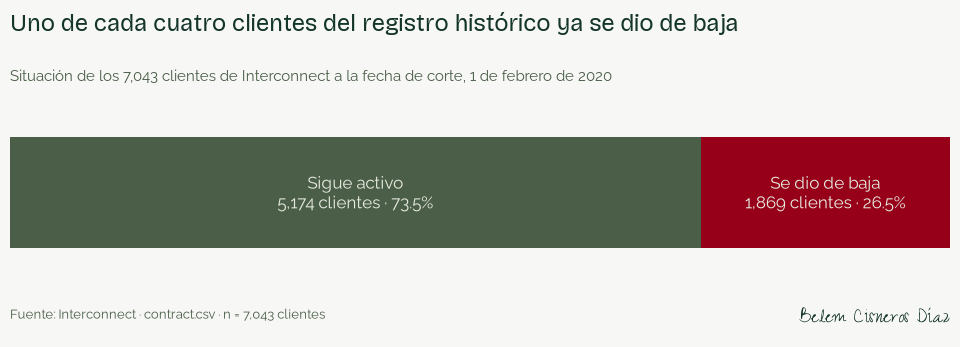

In [6]:
colores = {
    "fondo": "#F7F7F5",
    "activo": "#4A5E48",
    "baja": "#960018",
    "texto": "#14352A",
    "claro": "#E8EBE0",
}
fuente_titulo = "Bricolage Grotesque"
fuente_cuerpo = "Raleway"
fuente_firma = "Zeyada"

activos = int(conteo[0])
bajas = int(conteo[1])
total = activos + bajas

fig, ax = plt.subplots(figsize=(10, 3.6))
fig.patch.set_facecolor(colores["fondo"])
ax.set_facecolor(colores["fondo"])
fig.subplots_adjust(top=0.60, bottom=0.26, left=0.03, right=0.97)

ax.barh([0], [activos], color=colores["activo"], height=0.5)
ax.barh([0], [bajas], left=[activos], color=colores["baja"], height=0.5)

ax.text(
    activos / 2, 0,
    f"Sigue activo\n{activos:,} clientes · {activos / total:.1%}",
    ha="center", va="center", color=colores["claro"], fontsize=12, fontfamily=fuente_cuerpo,
)
ax.text(
    activos + bajas / 2, 0,
    f"Se dio de baja\n{bajas:,} clientes · {bajas / total:.1%}",
    ha="center", va="center", color=colores["claro"], fontsize=12, fontfamily=fuente_cuerpo,
)

ax.set_xlim(0, total)
ax.axis("off")

fig.text(
    0.03, 0.94, "Uno de cada cuatro clientes del registro histórico ya se dio de baja",
    fontsize=17, fontfamily=fuente_titulo, color=colores["texto"], ha="left", va="top",
)
fig.text(
    0.03, 0.78,
    f"Situación de los {total:,} clientes de Interconnect a la fecha de corte, {FECHA_CORTE_TEXTO}",
    fontsize=11, fontfamily=fuente_cuerpo, color=colores["activo"], ha="left", va="top",
)
fig.text(
    0.03, 0.08, f"Fuente: Interconnect · contract.csv · n = {total:,} clientes",
    fontsize=9, fontfamily=fuente_cuerpo, color=colores["activo"], ha="left",
)
fig.text(
    0.97, 0.07, "Belem Cisneros Díaz",
    fontsize=16, fontfamily=fuente_firma, color=colores["texto"], ha="right",
)

fig.savefig(RUTA_FIGURAS / "eda_balance_objetivo.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

#### 1.5 Qué distingue a los clientes que se van

Mi pregunta en esta sección no es cómo se distribuyen las variables, sino cuáles separan a los dos grupos. Considero que una variable sirve cuando la tasa de baja cambia de manera apreciable entre sus categorías; si todas sus categorías tienen la misma tasa, esa variable no aporta información aunque esté en los datos.

Trabajo sobre una **tabla de exploración**, que es una copia de `contract` con tres añadidos: la variable objetivo, la antigüedad en meses y la información de servicios traída de las otras tablas. La hice deliberadamente temporal. La tabla que alimenta a los modelos la construyo y la verifico en la sección 2.1, y quise separarlas para evitar que una transformación improvisada durante la exploración llegara al modelado sin control.

Dejo en inglés dos nombres técnicos que no tienen traducción de uso corriente: **DSL** (*digital subscriber line*), la conexión a internet sobre la línea telefónica de cobre, más lenta y más barata que la fibra óptica. Traduzco el resto de las categorías al español. No lo hago por estética: las figuras y las tablas de este informe las va a leer el equipo de marketing, y una leyenda que diga `Month-to-month` o `1` obliga a quien lee a traducir mentalmente antes de entender.

La antigüedad la calculo aquí con la regla que expliqué en la Etapa 1: para quien se dio de baja, los meses transcurridos entre el inicio y `EndDate`; para quien sigue activo, los meses entre el inicio y la fecha de corte. Insisto en que es la duración observada de la relación comercial.

In [7]:
exploracion = contract[["customerID", "Type", "PaymentMethod", "PaperlessBilling", "MonthlyCharges"]].copy()
exploracion["se_dio_de_baja"] = objetivo

termino = pd.to_datetime(contract["EndDate"].where(contract["EndDate"] != "No", FECHA_CORTE))
exploracion["antiguedad_meses"] = (
    (termino.dt.year - inicio.dt.year) * 12 + (termino.dt.month - inicio.dt.month)
)

exploracion = exploracion.merge(personal, on="customerID", how="left")
exploracion["servicio_internet"] = (
    contract["customerID"].map(internet.set_index("customerID")["InternetService"]).fillna("Sin internet")
)
exploracion["servicio_telefono"] = np.where(
    contract["customerID"].isin(phone["customerID"]), "Con línea telefónica", "Sin línea telefónica"
)

EQUIVALENCIAS = {
    "Type": {"Month-to-month": "Mes a mes", "One year": "Un año", "Two year": "Dos años"},
    "PaymentMethod": {
        "Electronic check": "Cheque electrónico",
        "Mailed check": "Cheque por correo",
        "Bank transfer (automatic)": "Transferencia automática",
        "Credit card (automatic)": "Tarjeta automática",
    },
    "PaperlessBilling": {"Yes": "Factura electrónica", "No": "Factura impresa"},
    "SeniorCitizen": {1: "Adulto mayor", 0: "Menor de 65 años"},
    "Partner": {"Yes": "Con pareja", "No": "Sin pareja"},
    "Dependents": {"Yes": "Con dependientes", "No": "Sin dependientes"},
    "gender": {"Female": "Mujer", "Male": "Hombre"},
    "servicio_internet": {"Fiber optic": "Fibra óptica", "DSL": "DSL", "Sin internet": "Sin internet"},
}

NOMBRES = {
    "Type": "Tipo de contrato",
    "PaymentMethod": "Método de pago",
    "servicio_internet": "Servicio de internet",
    "PaperlessBilling": "Tipo de factura",
    "SeniorCitizen": "Edad",
    "Dependents": "Dependientes económicos",
    "Partner": "Pareja",
    "servicio_telefono": "Servicio telefónico",
    "gender": "Género",
}

for columna, equivalencia in EQUIVALENCIAS.items():
    exploracion[columna] = exploracion[columna].map(equivalencia)

exploracion.head()

,customerID,Type,PaymentMethod,PaperlessBilling,MonthlyCharges,se_dio_de_baja,antiguedad_meses,gender,SeniorCitizen,Partner,Dependents,servicio_internet,servicio_telefono
0,7590-VHVEG,Mes a mes,Cheque electrónico,Factura electrónica,29.85,0,1,Mujer,Menor de 65 años,Con pareja,Sin dependientes,DSL,Sin línea telefónica
1,5575-GNVDE,Un año,Cheque por correo,Factura impresa,56.95,0,34,Hombre,Menor de 65 años,Sin pareja,Sin dependientes,DSL,Con línea telefónica
2,3668-QPYBK,Mes a mes,Cheque por correo,Factura electrónica,53.85,1,2,Hombre,Menor de 65 años,Sin pareja,Sin dependientes,DSL,Con línea telefónica
3,7795-CFOCW,Un año,Transferencia automática,Factura impresa,42.30,0,45,Hombre,Menor de 65 años,Sin pareja,Sin dependientes,DSL,Sin línea telefónica
4,9237-HQITU,Mes a mes,Cheque electrónico,Factura electrónica,70.70,1,2,Mujer,Menor de 65 años,Sin pareja,Sin dependientes,Fibra óptica,Con línea telefónica


In [8]:
def tasa_de_baja(columna):
    resumen = exploracion.groupby(columna, observed=True)["se_dio_de_baja"].agg(
        clientes="size", bajas="sum"
    )
    resumen["tasa de baja"] = resumen["bajas"] / resumen["clientes"]
    return resumen.sort_values("tasa de baja", ascending=False)


TASA_GENERAL = float(exploracion["se_dio_de_baja"].mean())

brechas = []
for columna, nombre in NOMBRES.items():
    resumen = tasa_de_baja(columna)
    brechas.append(
        {
            "variable": nombre,
            "mayor riesgo": resumen.index[0],
            "tasa": f"{resumen['tasa de baja'].iloc[0]:.1%}",
            "menor riesgo": resumen.index[-1],
            "tasa ": f"{resumen['tasa de baja'].iloc[-1]:.1%}",
            "brecha en puntos": round(
                (resumen["tasa de baja"].iloc[0] - resumen["tasa de baja"].iloc[-1]) * 100, 1
            ),
        }
    )

print(f"Tasa de baja general: {TASA_GENERAL:.1%}\n")
print("Antigüedad en meses y cargo mensual, por estado del cliente:")
print(
    exploracion.groupby("se_dio_de_baja")[["antiguedad_meses", "MonthlyCharges"]]
    .agg(["median", "mean"])
    .round(1)
    .rename(index={0: "Sigue activo", 1: "Se dio de baja"})
    .to_string()
)

pd.DataFrame(brechas).sort_values("brecha en puntos", ascending=False).reset_index(drop=True)

Tasa de baja general: 26.5%

Antigüedad en meses y cargo mensual, por estado del cliente:
               antiguedad_meses       MonthlyCharges      
                         median  mean         median  mean
se_dio_de_baja                                            
Sigue activo               38.0  37.6           64.4  61.3
Se dio de baja             10.0  18.0           79.6  74.4


,variable,mayor riesgo,tasa,menor riesgo,tasa,brecha en puntos
0,Tipo de contrato,Mes a mes,42.7%,Dos años,2.8%,39.9
1,Servicio de internet,Fibra óptica,41.9%,Sin internet,7.4%,34.5
2,Método de pago,Cheque electrónico,45.3%,Tarjeta automática,15.2%,30.0
3,Edad,Adulto mayor,41.7%,Menor de 65 años,23.6%,18.1
4,Tipo de factura,Factura electrónica,33.6%,Factura impresa,16.3%,17.2
5,Dependientes económicos,Sin dependientes,31.3%,Con dependientes,15.5%,15.8
6,Pareja,Sin pareja,33.0%,Con pareja,19.7%,13.3
7,Servicio telefónico,Con línea telefónica,26.7%,Sin línea telefónica,24.9%,1.8
8,Género,Mujer,26.9%,Hombre,26.2%,0.8


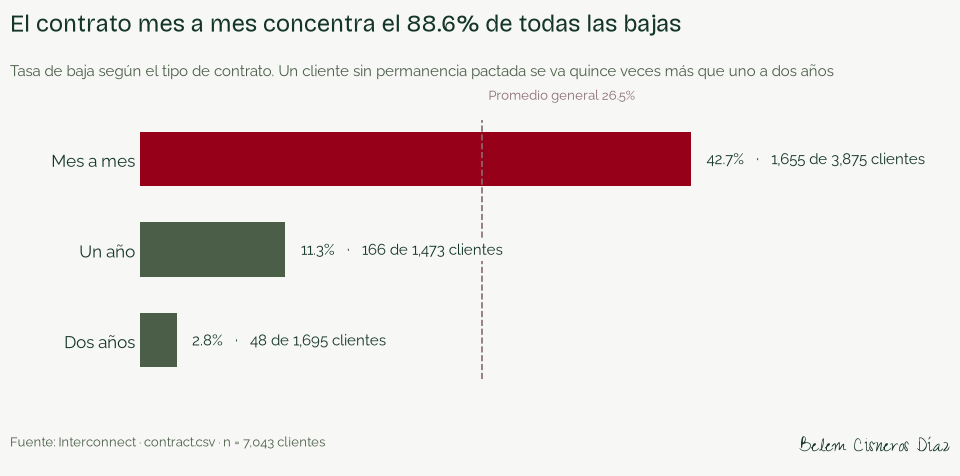

In [9]:
colores = {
    "fondo": "#F7F7F5",
    "activo": "#4A5E48",
    "baja": "#960018",
    "texto": "#14352A",
    "referencia": "#8A6A72",
}
fuente_titulo = "Bricolage Grotesque"
fuente_cuerpo = "Raleway"
fuente_firma = "Zeyada"

resumen = tasa_de_baja("Type").reindex(["Dos años", "Un año", "Mes a mes"])
participacion = resumen.loc["Mes a mes", "bajas"] / int(exploracion["se_dio_de_baja"].sum())

fig, ax = plt.subplots(figsize=(10, 4.8))
fig.patch.set_facecolor(colores["fondo"])
ax.set_facecolor(colores["fondo"])
fig.subplots_adjust(top=0.72, bottom=0.18, left=0.16, right=0.96)

barras = ax.barh(
    resumen.index,
    resumen["tasa de baja"],
    height=0.6,
    color=[colores["baja"] if v > TASA_GENERAL else colores["activo"] for v in resumen["tasa de baja"]],
)

for barra, (etiqueta, fila) in zip(barras, resumen.iterrows()):
    ax.text(
        fila["tasa de baja"] + 0.012,
        barra.get_y() + barra.get_height() / 2,
        f"{fila['tasa de baja']:.1%}   ·   {int(fila['bajas']):,} de {int(fila['clientes']):,} clientes",
        va="center", ha="left", fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"],
        bbox={"facecolor": colores["fondo"], "edgecolor": "none", "pad": 2},
    )

ax.axvline(TASA_GENERAL, color=colores["referencia"], linestyle="--", linewidth=1.2)
ax.text(
    TASA_GENERAL, 2.62, f"  Promedio general {TASA_GENERAL:.1%}",
    fontsize=9.5, fontfamily=fuente_cuerpo, color=colores["referencia"], va="bottom", ha="left",
)

ax.set_xlim(0, 0.62)
ax.set_xticks([])
ax.tick_params(axis="y", length=0, labelsize=12)
for etiqueta in ax.get_yticklabels():
    etiqueta.set_fontfamily(fuente_cuerpo)
    etiqueta.set_color(colores["texto"])
for lado in ax.spines.values():
    lado.set_visible(False)

fig.text(
    0.03, 0.95,
    f"El contrato mes a mes concentra el {participacion:.1%} de todas las bajas",
    fontsize=17, fontfamily=fuente_titulo, color=colores["texto"], ha="left", va="top",
)
fig.text(
    0.03, 0.84,
    "Tasa de baja según el tipo de contrato. Un cliente sin permanencia pactada se va quince veces más que uno a dos años",
    fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["activo"], ha="left", va="top",
)
fig.text(
    0.03, 0.04, f"Fuente: Interconnect · contract.csv · n = {len(exploracion):,} clientes",
    fontsize=9, fontfamily=fuente_cuerpo, color=colores["activo"], ha="left",
)
fig.text(
    0.97, 0.03, "Belem Cisneros Díaz",
    fontsize=16, fontfamily=fuente_firma, color=colores["texto"], ha="right",
)

fig.savefig(RUTA_FIGURAS / "eda_bajas_por_contrato.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

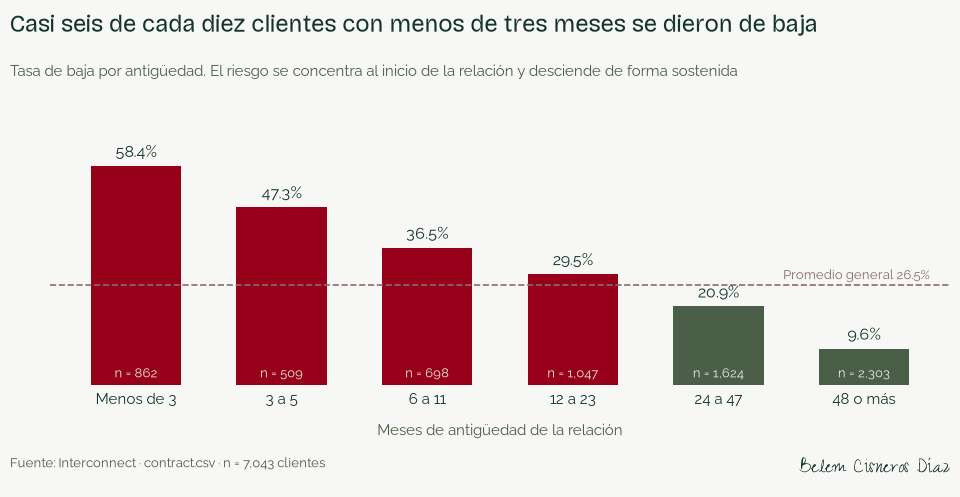

In [10]:
colores = {
    "fondo": "#F7F7F5",
    "activo": "#4A5E48",
    "baja": "#960018",
    "texto": "#14352A",
    "referencia": "#8A6A72",
}
fuente_titulo = "Bricolage Grotesque"
fuente_cuerpo = "Raleway"
fuente_firma = "Zeyada"

TRAMOS = [-1, 2, 5, 11, 23, 47, 1000]
ETIQUETAS = ["Menos de 3", "3 a 5", "6 a 11", "12 a 23", "24 a 47", "48 o más"]
exploracion["tramo_antiguedad"] = pd.cut(
    exploracion["antiguedad_meses"], TRAMOS, labels=ETIQUETAS
)
resumen = tasa_de_baja("tramo_antiguedad").reindex(ETIQUETAS)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(colores["fondo"])
ax.set_facecolor(colores["fondo"])
fig.subplots_adjust(top=0.71, bottom=0.20, left=0.07, right=0.97)

barras = ax.bar(
    resumen.index,
    resumen["tasa de baja"],
    width=0.62,
    color=[colores["baja"] if v > TASA_GENERAL else colores["activo"] for v in resumen["tasa de baja"]],
)

for barra, (etiqueta, fila) in zip(barras, resumen.iterrows()):
    ax.text(
        barra.get_x() + barra.get_width() / 2, fila["tasa de baja"] + 0.014,
        f"{fila['tasa de baja']:.1%}",
        ha="center", va="bottom", fontsize=11.5, fontfamily=fuente_cuerpo, color=colores["texto"],
    )
    ax.text(
        barra.get_x() + barra.get_width() / 2, 0.012,
        f"n = {int(fila['clientes']):,}",
        ha="center", va="bottom", fontsize=9, fontfamily=fuente_cuerpo, color="#E8EBE0",
    )

ax.axhline(TASA_GENERAL, color=colores["referencia"], linestyle="--", linewidth=1.2)
ax.text(
    5.45, TASA_GENERAL + 0.008, f"Promedio general {TASA_GENERAL:.1%}",
    fontsize=9.5, fontfamily=fuente_cuerpo, color=colores["referencia"], va="bottom", ha="right",
)

ax.set_ylim(0, 0.68)
ax.set_yticks([])
ax.tick_params(axis="x", length=0, labelsize=11)
for etiqueta in ax.get_xticklabels():
    etiqueta.set_fontfamily(fuente_cuerpo)
    etiqueta.set_color(colores["texto"])
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_xlabel("Meses de antigüedad de la relación", fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["activo"], labelpad=10)

fig.text(
    0.03, 0.95,
    f"Casi seis de cada diez clientes con menos de tres meses se dieron de baja",
    fontsize=17, fontfamily=fuente_titulo, color=colores["texto"], ha="left", va="top",
)
fig.text(
    0.03, 0.845,
    "Tasa de baja por antigüedad. El riesgo se concentra al inicio de la relación y desciende de forma sostenida",
    fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["activo"], ha="left", va="top",
)
fig.text(
    0.03, 0.035, f"Fuente: Interconnect · contract.csv · n = {len(exploracion):,} clientes",
    fontsize=9, fontfamily=fuente_cuerpo, color=colores["activo"], ha="left",
)
fig.text(
    0.97, 0.025, "Belem Cisneros Díaz",
    fontsize=16, fontfamily=fuente_firma, color=colores["texto"], ha="right",
)

fig.savefig(RUTA_FIGURAS / "eda_bajas_por_antiguedad.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

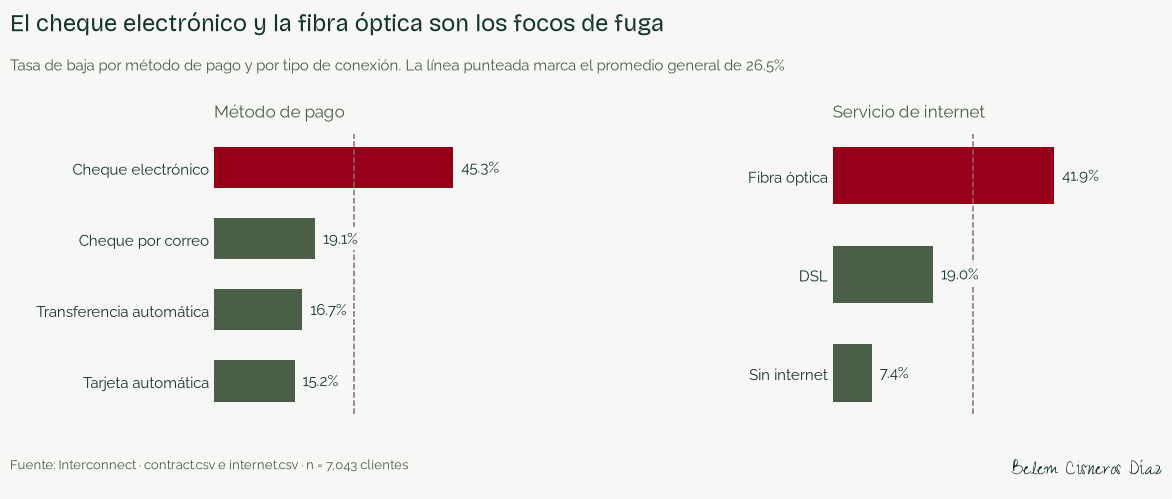

In [11]:
colores = {
    "fondo": "#F7F7F5",
    "activo": "#4A5E48",
    "baja": "#960018",
    "texto": "#14352A",
    "referencia": "#8A6A72",
}
fuente_titulo = "Bricolage Grotesque"
fuente_cuerpo = "Raleway"
fuente_firma = "Zeyada"

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(colores["fondo"])
fig.subplots_adjust(top=0.70, bottom=0.14, left=0.19, right=0.97, wspace=0.95)

for eje, columna, subtitulo in zip(
    ejes, ["PaymentMethod", "servicio_internet"], ["Método de pago", "Servicio de internet"]
):
    resumen = tasa_de_baja(columna).sort_values("tasa de baja")
    eje.set_facecolor(colores["fondo"])
    barras = eje.barh(
        resumen.index,
        resumen["tasa de baja"],
        height=0.58,
        color=[colores["baja"] if v > TASA_GENERAL else colores["activo"] for v in resumen["tasa de baja"]],
    )
    for barra, (etiqueta, fila) in zip(barras, resumen.iterrows()):
        eje.text(
            fila["tasa de baja"] + 0.015, barra.get_y() + barra.get_height() / 2,
            f"{fila['tasa de baja']:.1%}",
            va="center", ha="left", fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"],
            bbox={"facecolor": colores["fondo"], "edgecolor": "none", "pad": 2},
        )
    eje.axvline(TASA_GENERAL, color=colores["referencia"], linestyle="--", linewidth=1.1)
    eje.set_xlim(0, 0.60)
    eje.set_xticks([])
    eje.tick_params(axis="y", length=0, labelsize=11)
    for etiqueta in eje.get_yticklabels():
        etiqueta.set_fontfamily(fuente_cuerpo)
        etiqueta.set_color(colores["texto"])
    for lado in eje.spines.values():
        lado.set_visible(False)
    eje.set_title(subtitulo, fontsize=12, fontfamily=fuente_cuerpo, color=colores["activo"], loc="left", pad=12)

fig.text(
    0.02, 0.95,
    "El cheque electrónico y la fibra óptica son los focos de fuga",
    fontsize=17, fontfamily=fuente_titulo, color=colores["texto"], ha="left", va="top",
)
fig.text(
    0.02, 0.855,
    f"Tasa de baja por método de pago y por tipo de conexión. La línea punteada marca el promedio general de {TASA_GENERAL:.1%}",
    fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["activo"], ha="left", va="top",
)
fig.text(
    0.02, 0.03,
    f"Fuente: Interconnect · contract.csv e internet.csv · n = {len(exploracion):,} clientes",
    fontsize=9, fontfamily=fuente_cuerpo, color=colores["activo"], ha="left",
)
fig.text(
    0.98, 0.02, "Belem Cisneros Díaz",
    fontsize=16, fontfamily=fuente_firma, color=colores["texto"], ha="right",
)

fig.savefig(RUTA_FIGURAS / "eda_bajas_por_pago_e_internet.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

#### 1.6 Conclusiones del análisis exploratorio

Cierro la exploración con la lista de hallazgos y la decisión concreta que tomé a partir de cada uno. Esta tabla es mi puente hacia el preprocesamiento: quiero que quede claro que ninguna transformación de la sección 2 es arbitraria, porque todas responden a una línea de aquí.

| Hallazgo | Evidencia | Qué decidí |
|---|---|---|
| `customerID` es único en las cuatro tablas y ningún archivo trae nulos propios | Sección 1.3 | Unión izquierda desde `contract`, con verificación del número de filas inmediatamente después (2.1) |
| El 26.5 % de los clientes del registro se dio de baja | Sección 1.4 | El desbalance es moderado. Descarto la exactitud como métrica, estratifico las tres particiones y aplico técnicas de balanceo solo sobre el entrenamiento (2.6 y 4.1) |
| Todas las fechas, de inicio y de término, caen el día 1 del mes | Sección 1.3 | Mido la antigüedad en **meses enteros**. Medirla en días le atribuiría al dato una precisión que no tiene |
| La fecha más reciente observada es el 1 de febrero de 2020 | Sección 1.4 | Adopto esa fecha de corte como referencia para medir la antigüedad de los clientes activos (2.3) |
| `TotalCharges` llegó como texto, con 11 celdas vacías que corresponden a clientes dados de alta en febrero de 2020 y todavía activos | Sección 1.3 | Convierto a número y asigno 0 a esos 11 registros: su monto acumulado a la fecha de corte es efectivamente cero (2.3) |
| El contrato mes a mes tiene una tasa de baja de 42.7 % frente a 2.8 % del contrato a dos años, y concentra el 88.6 % de todas las bajas | Sección 1.5 | La trato como variable de primer orden. La conservo y encabeza los segmentos de acción comercial que propongo en 5.5 |
| El 58.4 % de los clientes con menos de tres meses se dio de baja, contra 9.6 % de quienes llevan cuatro años o más | Sección 1.5 | Además de confirmar la antigüedad como predictor, me indica que la retención debe actuar en los primeros meses y no cuando el cliente ya avisó |
| El cheque electrónico alcanza 45.3 % de baja y la fibra óptica 41.9 % | Sección 1.5 | Conservo ambas. Como no existe un orden natural entre métodos de pago ni entre tipos de conexión, las codifico con One-Hot para el modelo lineal (2.5) |
| Los clientes sin servicio de internet tienen la tasa más baja del conjunto, 7.4 % | Sección 1.5 | Me confirma que la ausencia de servicio es información y no un dato faltante, así que el indicador `tiene_internet` entra al modelo (2.4) |
| Quienes se dan de baja pagan en promedio 74.4 de cargo mensual frente a 61.3 de quienes permanecen | Sección 1.5 | Conservo el cargo mensual como variable y lo uso además como base del cálculo de ingreso en riesgo (5.2) |
| El género separa 0.8 puntos porcentuales y tener línea telefónica, 1.8 | Sección 1.5 | Decido no eliminarlas todavía. Una brecha pequeña por sí sola no descarta que la variable aporte en combinación con otras, así que dejo que la importancia por permutación lo resuelva con evidencia (4.5). Consideré descartarlas aquí para simplificar y lo descarté porque sería una decisión tomada antes de la prueba |

**En qué ajusté mi plan inicial**

En la Etapa 1 propuse medir la antigüedad en días o en meses, sin decidirme. La exploración resolvió la duda: como todos los registros caen el día 1 del mes, la unidad es el mes. También confirmó el desbalance que yo anticipaba y me permitió acotarlo: 26.5 % no es un caso extremo, de modo que espero que el ajuste de pesos baste y dejo el sobremuestreo como comparación y no como recurso indispensable.

Con esto doy por cerrado el análisis exploratorio. Registro las cifras en el diccionario `metricas`, que se escribirá en `resultados/metricas.json` al final del notebook.

In [12]:
def a_diccionario(serie):
    return {str(indice): round(float(valor), 4) for indice, valor in serie.items()}


metricas["eda"] = {
    "clientes": int(len(exploracion)),
    "bajas": int(exploracion["se_dio_de_baja"].sum()),
    "tasa_baja_general": round(TASA_GENERAL, 4),
    "participacion_bajas_mes_a_mes": round(
        float(tasa_de_baja("Type").loc["Mes a mes", "bajas"] / exploracion["se_dio_de_baja"].sum()), 4
    ),
    "tasa_por_contrato": a_diccionario(tasa_de_baja("Type")["tasa de baja"]),
    "tasa_por_antiguedad": a_diccionario(tasa_de_baja("tramo_antiguedad")["tasa de baja"]),
    "tasa_por_metodo_pago": a_diccionario(tasa_de_baja("PaymentMethod")["tasa de baja"]),
    "tasa_por_servicio_internet": a_diccionario(tasa_de_baja("servicio_internet")["tasa de baja"]),
    "antiguedad_mediana_meses": {
        "activo": float(exploracion.loc[exploracion["se_dio_de_baja"] == 0, "antiguedad_meses"].median()),
        "baja": float(exploracion.loc[exploracion["se_dio_de_baja"] == 1, "antiguedad_meses"].median()),
    },
    "cargo_mensual_promedio": {
        "activo": round(float(exploracion.loc[exploracion["se_dio_de_baja"] == 0, "MonthlyCharges"].mean()), 2),
        "baja": round(float(exploracion.loc[exploracion["se_dio_de_baja"] == 1, "MonthlyCharges"].mean()), 2),
    },
}

metricas["eda"]

{'clientes': 7043,
 'bajas': 1869,
 'tasa_baja_general': 0.2654,
 'participacion_bajas_mes_a_mes': 0.8855,
 'tasa_por_contrato': {'Mes a mes': 0.4271,
  'Un año': 0.1127,
  'Dos años': 0.0283},
 'tasa_por_antiguedad': {'Menos de 3': 0.5835,
  '3 a 5': 0.4735,
  '6 a 11': 0.3653,
  '12 a 23': 0.2951,
  '24 a 47': 0.2087,
  '48 o más': 0.0964},
 'tasa_por_metodo_pago': {'Cheque electrónico': 0.4529,
  'Cheque por correo': 0.1911,
  'Transferencia automática': 0.1671,
  'Tarjeta automática': 0.1524},
 'tasa_por_servicio_internet': {'Fibra óptica': 0.4189,
  'DSL': 0.1896,
  'Sin internet': 0.074},
 'antiguedad_mediana_meses': {'activo': 38.0, 'baja': 10.0},
 'cargo_mensual_promedio': {'activo': 61.27, 'baja': 74.44}}

### 2. Preprocesamiento e ingeniería de características

#### 2.1 Unión de las cuatro tablas

Uno las cuatro tablas con `contract` como base y uniones izquierdas sucesivas sobre `customerID`. La tabla base manda: el resultado debe conservar exactamente sus 7 043 filas, porque cada fila es un cliente y ninguna operación de este notebook puede crear ni perder clientes. Prefiero verificarlo en la misma celda antes que suponerlo.

Los nulos que aparecen son el resultado esperado de la unión y tienen un significado concreto: 1 526 clientes no contrataron internet y 682 no contrataron línea telefónica. Los cuento por columna para dejar constancia de su magnitud antes de tratarlos en la sección 2.4.

In [13]:
datos = (
    contract
    .merge(personal, on="customerID", how="left")
    .merge(internet, on="customerID", how="left")
    .merge(phone, on="customerID", how="left")
)

print("Filas en la tabla base:", len(contract))
print("Filas después de unir: ", len(datos))
print("Se conservó el número de clientes:", len(datos) == len(contract))
print("customerID sigue siendo único:", datos["customerID"].is_unique)
print("Columnas resultantes:", datos.shape[1])

nulos = datos.isna().sum()
pd.DataFrame(
    {
        "columna": nulos[nulos > 0].index,
        "nulos": nulos[nulos > 0].to_numpy(),
        "origen": ["internet.csv"] * 7 + ["phone.csv"],
    }
)

Filas en la tabla base: 7043
Filas después de unir:  7043
Se conservó el número de clientes: True
customerID sigue siendo único: True
Columnas resultantes: 20


,columna,nulos,origen
0,InternetService,1526,internet.csv
1,OnlineSecurity,1526,internet.csv
2,OnlineBackup,1526,internet.csv
3,DeviceProtection,1526,internet.csv
4,TechSupport,1526,internet.csv
5,StreamingTV,1526,internet.csv
6,StreamingMovies,1526,internet.csv
7,MultipleLines,682,phone.csv


#### 2.2 Variable objetivo

Aplico sobre la tabla unida la misma regla que usé en el análisis exploratorio: una fecha en `EndDate` significa que el cliente se dio de baja, el texto `No` significa que sigue activo. El resultado debe coincidir exactamente con el conteo de la sección 1.4, 1 869 bajas, y lo compruebo en la celda. Si no coincidiera, sabría que la unión alteró los datos y que todo lo que sigue sería inválido.

Llamé a la variable `se_dio_de_baja` y no `churn` ni `target`. El nombre va a aparecer en tablas y figuras que lee el equipo de marketing, y un nombre en español les evita una traducción mental en cada lectura.

#### 2.3 Antigüedad y eliminación de la fecha de término

Esta es la decisión más delicada de todo mi preprocesamiento y quiero explicarla con detalle. `EndDate` es, al mismo tiempo, la fuente de la variable objetivo y la fuente de la antigüedad de los clientes que se dieron de baja. La uso para construir ambas y acto seguido la elimino junto con `BeginDate`, porque un cliente real sobre el que haya que decidir hoy no viene con fecha de término escrita: conservarla haría que el modelo leyera la respuesta en lugar de anticiparla, y su desempeño se desplomaría en producción. A eso se le llama **fuga de información**.

La antigüedad la mido en meses enteros, como concluí en el análisis exploratorio, y con dos referencias distintas según el caso: para quien se dio de baja, los meses entre `BeginDate` y `EndDate`; para quien sigue activo, los meses entre `BeginDate` y la fecha de corte. Es la duración observada de la relación comercial hasta donde llegan los datos. Lo declaro de forma explícita porque sé que es el punto por el que me preguntarían: la antigüedad de un cliente que canceló está medida hasta su cancelación, y esa es la única definición posible con un registro histórico.

Quiero adelantarme a la objeción evidente: si la antigüedad de quien canceló se mide usando `EndDate`, ¿no es eso fuga de información por la puerta de atrás? Mi respuesta es que no. La antigüedad no es una variable desconocida en el momento de predecir: de un cliente activo siempre se sabe cuántos meses lleva, porque es un dato de su expediente. Lo que no se conoce —y por eso lo elimino— es la fecha en que terminará su contrato. La antigüedad registra la duración observada de la relación hasta donde llegan los datos; `EndDate` registra el desenlace. Va en la misma dirección la indicación que da el enunciado para esta etapa, cuando pregunta cómo transformar *las fechas de inicio y fin* en una variable numérica útil para el modelo. Dicho eso, reconozco que es la variable más influyente del modelo con diferencia, y en la sección 4.5 lo cuantifico.

`TotalCharges` pasa a número y los once registros vacíos quedan en 0, que es su valor real: son clientes dados de alta en la fecha de corte que todavía no acumulan facturación.

Termino poniendo `customerID` como índice. Un identificador no es una característica, y si lo dejara como columna correría el riesgo de que entrara al modelo por descuido. Como índice sigue disponible para rastrear clientes y queda fuera del alcance de los algoritmos.

Cierro la celda con una comprobación explícita de que ninguna columna derivada de la fecha de término sobrevivió.

In [14]:
datos["se_dio_de_baja"] = (datos["EndDate"] != "No").astype("int8")

bajas_eda = int(exploracion["se_dio_de_baja"].sum())
bajas_modelado = int(datos["se_dio_de_baja"].sum())
print("Bajas contadas en el análisis exploratorio:", bajas_eda)
print("Bajas en la tabla de modelado:          ", bajas_modelado)
print("Coinciden:", bajas_eda == bajas_modelado)

inicio_contrato = pd.to_datetime(datos["BeginDate"])
termino_contrato = pd.to_datetime(datos["EndDate"].where(datos["EndDate"] != "No", FECHA_CORTE))
datos["antiguedad_meses"] = (
    (termino_contrato.dt.year - inicio_contrato.dt.year) * 12
    + (termino_contrato.dt.month - inicio_contrato.dt.month)
).astype("int16")

datos["TotalCharges"] = pd.to_numeric(datos["TotalCharges"], errors="coerce").fillna(0.0)

datos = datos.drop(columns=["BeginDate", "EndDate"]).set_index("customerID")

rastros_de_fecha = [c for c in datos.columns if "Date" in c or "End" in c]
print("\nColumnas derivadas de la fecha de término que sobreviven:", rastros_de_fecha)
print("Antigüedad en meses · mínimo:", int(datos["antiguedad_meses"].min()), "· máximo:", int(datos["antiguedad_meses"].max()))
print("TotalCharges en 0:", int((datos["TotalCharges"] == 0).sum()), "registros")

datos.head()

Bajas contadas en el análisis exploratorio: 1869
Bajas en la tabla de modelado:           1869
Coinciden: True

Columnas derivadas de la fecha de término que sobreviven: []
Antigüedad en meses · mínimo: 0 · máximo: 72
TotalCharges en 0: 11 registros


,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines,se_dio_de_baja,antiguedad_meses
customerID,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Month-to-month,Yes,Electronic check,29.85,29.85,Female,0,Yes,No,DSL,No,Yes,No,No,No,No,NaN,0,1
5575-GNVDE,One year,No,Mailed check,56.95,1889.50,Male,0,No,No,DSL,Yes,No,Yes,No,No,No,No,0,34
3668-QPYBK,Month-to-month,Yes,Mailed check,53.85,108.15,Male,0,No,No,DSL,Yes,Yes,No,No,No,No,No,1,2
7795-CFOCW,One year,No,Bank transfer (automatic),42.30,1840.75,Male,0,No,No,DSL,Yes,No,Yes,Yes,No,No,NaN,0,45
9237-HQITU,Month-to-month,Yes,Electronic check,70.70,151.65,Female,0,No,No,Fiber optic,No,No,No,No,No,No,No,1,2


#### 2.4 Ausencia de servicio

Los 1 526 nulos de internet y los 682 de telefonía no son datos faltantes: son clientes que no contrataron ese servicio. Relleno cada columna con una categoría que lo dice con todas sus letras, `Sin internet` y `Sin línea telefónica`. Descarté dos alternativas antes de llegar a esta. Imputar con la moda inventaría un servicio que el cliente nunca tuvo. Rellenar con `No` confundiría dos situaciones distintas: "tiene internet pero no contrató el antivirus" y "no tiene internet en absoluto", que son clientes con comportamientos opuestos.

**Dónde me aparté de mi plan inicial.** En la Etapa 1 propuse añadir además dos indicadores binarios, `tiene_internet` y `tiene_telefono`. Al llegar aquí me di cuenta de que serían redundantes: como la ausencia quedó codificada como una categoría propia, la codificación One-Hot de la sección siguiente generará por sí sola una columna `Sin internet` que es exactamente ese indicador. Duplicar una variable no agrega información y sí complica la lectura de los coeficientes del modelo lineal.

En su lugar creé una variable que no había previsto y que sí aporta algo nuevo: `combinacion_servicios`, con tres valores posibles, solo teléfono, solo internet o ambos. No es redundante porque expresa una **interacción**, es decir el efecto conjunto de dos variables, que un modelo lineal no puede deducir por su cuenta a partir de las columnas por separado. Me pareció además que es la forma en que el equipo comercial piensa su cartera, de modo que reaparece en los perfiles de riesgo de la sección 5.5.

Cierro la celda confirmando que no queda un solo nulo en la tabla y mostrando la tasa de baja de cada combinación, que es la evidencia de que la variable informa.

In [15]:
COLUMNAS_INTERNET = [
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]

con_internet = datos["InternetService"].notna()
con_telefono = datos["MultipleLines"].notna()

datos[COLUMNAS_INTERNET] = datos[COLUMNAS_INTERNET].fillna("Sin internet")
datos["MultipleLines"] = datos["MultipleLines"].fillna("Sin línea telefónica")

datos["combinacion_servicios"] = np.select(
    [con_internet & con_telefono, con_internet & ~con_telefono, ~con_internet & con_telefono],
    ["Internet y teléfono", "Solo internet", "Solo teléfono"],
    default="Sin servicios",
)

print("Nulos restantes en la tabla de modelado:", int(datos.isna().sum().sum()))
print("Columnas de la tabla:", datos.shape[1])

resumen_servicios = datos.groupby("combinacion_servicios", observed=True)["se_dio_de_baja"].agg(
    clientes="size", bajas="sum"
)
resumen_servicios["tasa de baja"] = (
    resumen_servicios["bajas"] / resumen_servicios["clientes"]
).map("{:.1%}".format)
resumen_servicios.sort_values("clientes", ascending=False)

Nulos restantes en la tabla de modelado: 0
Columnas de la tabla: 20


,clientes,bajas,tasa de baja
combinacion_servicios,,,
Internet y teléfono,4835,1586,32.8%
Solo teléfono,1526,113,7.4%
Solo internet,682,170,24.9%


#### 2.5 Codificación de las variables categóricas

Los algoritmos operan con números, así que las categorías deben convertirse. Uso dos esquemas distintos porque los dos tipos de modelo que voy a entrenar entienden los números de manera diferente, y aplicarles la misma codificación penalizaría a uno de los dos.

| Esquema | Para qué modelo | Por qué lo elegí |
|---|---|---|
| **One-Hot** (*una activa*): una columna binaria por categoría | Regresión logística | Un modelo lineal interpreta los números como magnitudes ordenadas. Si codificara los métodos de pago como 0, 1, 2 y 3, el modelo asumiría que una transferencia vale el triple que un cheque electrónico, lo cual no significa nada. One-Hot elimina ese orden inventado. Uso `drop="if_binary"` para que las variables de sí o no generen una sola columna en lugar de dos redundantes |
| **Ordinal**: un entero por categoría | Bosque aleatorio y LightGBM | Un árbol no interpreta magnitudes: parte el espacio en cortes sucesivos, de modo que el entero es apenas una etiqueta. Aplicarles One-Hot sería contraproducente, porque multiplicaría las columnas y diluiría cada categoría en una variable casi siempre apagada, lo que degrada la calidad de los cortes |

Monté ambos esquemas dentro de un `ColumnTransformer`, que aplica una transformación distinta a cada grupo de columnas, y este a su vez va dentro de un `Pipeline` junto con el modelo. No lo hice por estilo: es lo que me garantiza que el escalado y la codificación **se ajusten únicamente con los datos de entrenamiento** en cada partición de la validación cruzada. Un escalador que hubiera visto el conjunto de prueba contaminaría la evaluación, y ese error es invisible si el preprocesamiento se hace a mano sobre la tabla completa antes de dividir.

El escalado lo aplico solo en el esquema lineal. La regresión logística lo necesita porque compara coeficientes entre variables de escalas distintas, como un cargo mensual de 118 contra una antigüedad de 72 meses; los modelos de árboles son indiferentes a la escala, ya que solo comparan valores dentro de cada variable.

In [16]:
COLUMNAS_NUMERICAS = ["MonthlyCharges", "TotalCharges", "antiguedad_meses"]
COLUMNAS_CATEGORICAS = [
    columna for columna in datos.columns
    if columna not in COLUMNAS_NUMERICAS + ["se_dio_de_baja"]
]

preprocesador_lineal = ColumnTransformer(
    [
        ("categoricas", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), COLUMNAS_CATEGORICAS),
        ("numericas", StandardScaler(), COLUMNAS_NUMERICAS),
    ]
)

preprocesador_arboles = ColumnTransformer(
    [
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), COLUMNAS_CATEGORICAS),
        ("numericas", "passthrough", COLUMNAS_NUMERICAS),
    ]
)

print(f"Variables numéricas ({len(COLUMNAS_NUMERICAS)}):", ", ".join(COLUMNAS_NUMERICAS))
print(f"\nVariables categóricas ({len(COLUMNAS_CATEGORICAS)}):")
for columna in COLUMNAS_CATEGORICAS:
    print(f"  {columna}: {datos[columna].nunique()} categorías")

Variables numéricas (3): MonthlyCharges, TotalCharges, antiguedad_meses

Variables categóricas (16):
  Type: 3 categorías
  PaperlessBilling: 2 categorías
  PaymentMethod: 4 categorías
  gender: 2 categorías
  SeniorCitizen: 2 categorías
  Partner: 2 categorías
  Dependents: 2 categorías
  InternetService: 3 categorías
  OnlineSecurity: 3 categorías
  OnlineBackup: 3 categorías
  DeviceProtection: 3 categorías
  TechSupport: 3 categorías
  StreamingTV: 3 categorías
  StreamingMovies: 3 categorías
  MultipleLines: 3 categorías
  combinacion_servicios: 3 categorías


#### 2.6 División en entrenamiento, validación y prueba

Divido en tres partes con proporciones 60 / 20 / 20, y le asigné a cada una una función que no se puede mezclar con las otras:

| Partición | Para qué la uso | Cuántas veces la uso |
|---|---|---|
| Entrenamiento (60 %) | El modelo aprende de ella y sobre ella aplico las técnicas de balanceo | En cada entrenamiento |
| Validación (20 %) | Comparar modelos y elegir hiperparámetros | Tantas veces como haga falta |
| Prueba (20 %) | Estimar el desempeño ante clientes nuevos | **Una sola vez**, con el modelo ya elegido |

Reservo la prueba hasta el final porque cada vez que se mira un conjunto para tomar una decisión, ese conjunto deja de ser una simulación honesta de datos nuevos. Si eligiera el modelo mirando la prueba, estaría eligiendo el que mejor se ajusta a esos 1 409 clientes en particular y la cifra que reportaría sería optimista.

La división es **estratificada**, es decir que conserva en las tres partes la misma proporción de bajas que en el conjunto completo. Con un 26.5 % de clase minoritaria, una división al azar podría dejar proporciones distintas entre partes y volver incomparables las métricas. Lo verifico en la celda en lugar de confiar en el parámetro.

Como `train_test_split` divide en dos, la apliqué dos veces: primero separo el 40 % que no es entrenamiento y luego parto ese bloque por la mitad. Puse la semilla `RANDOM_STATE` en las dos llamadas para que la división sea idéntica en cada ejecución.

In [17]:
X = datos.drop(columns=["se_dio_de_baja"])
y = datos["se_dio_de_baja"]

X_entrenamiento, X_resto, y_entrenamiento, y_resto = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
X_validacion, X_prueba, y_validacion, y_prueba = train_test_split(
    X_resto, y_resto, test_size=0.5, stratify=y_resto, random_state=RANDOM_STATE
)

particiones = {
    "Entrenamiento": y_entrenamiento,
    "Validación": y_validacion,
    "Prueba": y_prueba,
}

metricas["particiones"] = {
    "entrenamiento": int(len(y_entrenamiento)),
    "validacion": int(len(y_validacion)),
    "prueba": int(len(y_prueba)),
}

columnas_lineales = preprocesador_lineal.fit(X_entrenamiento).get_feature_names_out()
print("Columnas de entrada:", X.shape[1])
print("Columnas tras la codificación One-Hot:", len(columnas_lineales))
print("Columnas tras la codificación ordinal:", len(COLUMNAS_CATEGORICAS) + len(COLUMNAS_NUMERICAS))

pd.DataFrame(
    {
        "partición": list(particiones),
        "clientes": [len(serie) for serie in particiones.values()],
        "proporción del total": [f"{len(serie) / len(y):.1%}" for serie in particiones.values()],
        "bajas": [int(serie.sum()) for serie in particiones.values()],
        "tasa de baja": [f"{serie.mean():.2%}" for serie in particiones.values()],
    }
)

Columnas de entrada: 19
Columnas tras la codificación One-Hot: 42
Columnas tras la codificación ordinal: 19


,partición,clientes,proporción del total,bajas,tasa de baja
0,Entrenamiento,4225,60.0%,1121,26.53%
1,Validación,1409,20.0%,374,26.54%
2,Prueba,1409,20.0%,374,26.54%


### 3. Selección de variables y modelos baseline

**Por qué no descarto variables todavía.** Entro al modelado con las 19 variables disponibles, sin eliminar ninguna a mano. Decidí así porque una eliminación previa basada en la brecha que vi en el EDA sería una decisión tomada antes de la prueba: una variable con poca señal por sí sola puede aportar en combinación con otras, y los tres modelos que voy a entrenar penalizan o ignoran por su cuenta lo que no informa. Dejo la selección con evidencia para la sección 4.5, donde la importancia por permutación mide cuánto se degrada el desempeño real al desordenar cada variable.

#### 3.1 Función común de evaluación

Escribí una sola función para evaluar todos los modelos. Lo hice así porque quería estar segura de que las diferencias entre ellos vinieran de los modelos y no de haber calculado las métricas de forma distinta en cada caso.

Cuidé especialmente que el AUC-ROC reciba `predict_proba[:, 1]`, es decir las probabilidades y no las clases ya predichas. Me detengo en este punto porque si le paso las clases la función no marca ningún error y aun así el resultado deja de ser válido: estaría midiendo la capacidad de ordenar clientes con una variable que solo toma dos valores.

Añadí la **precisión** a las dos métricas principales. La incluyo porque el Recall me dice a cuántos clientes en riesgo alcanzo, pero no cuántas promociones gastaría en quien no pensaba irse, y necesito las dos para elegir el umbral de la sección 5.4.

In [18]:
def evaluar(nombre, modelo, caracteristicas, objetivo_real):
    probabilidades = modelo.predict_proba(caracteristicas)[:, 1]
    predicciones = modelo.predict(caracteristicas)
    return {
        "modelo": nombre,
        "AUC-ROC": roc_auc_score(objetivo_real, probabilidades),
        "Recall": recall_score(objetivo_real, predicciones),
        "Precisión": precision_score(objetivo_real, predicciones, zero_division=0),
    }


def formatear(tabla, formatos=None, indice=None):
    presentacion = tabla.copy()
    formatos = formatos or {}
    for columna in presentacion.columns:
        if columna in formatos:
            presentacion[columna] = presentacion[columna].map(formatos[columna].format)
        elif presentacion[columna].dtype.kind == "f":
            presentacion[columna] = presentacion[columna].map("{:.4f}".format)
    if indice is not None:
        presentacion = presentacion.set_index(indice)
    return presentacion

#### 3.2 Modelo constante

El `DummyClassifier` con la estrategia de clase mayoritaria predice que **nadie** se va a dar de baja. No lo incluyo como modelo serio, sino como la vara con la que mido si los demás aportan algo: cualquier modelo que no lo supere con holgura no justificaría el esfuerzo de mantenerlo en producción.

#### 3.3 Tres modelos sin técnicas de balanceo

Entreno tres modelos de familias distintas, todos sobre el conjunto de entrenamiento y **sin** ninguna corrección del desbalance, que es lo que pide esta etapa. Quiero medir de dónde partimos y cuánto daña el desbalance antes de intentar corregirlo.

| Modelo | Familia | Por qué lo incluyo |
|---|---|---|
| Regresión logística | Lineal | Es interpretable: cada coeficiente dice en qué dirección y con qué fuerza empuja una variable |
| Bosque aleatorio | Conjunto de árboles en paralelo | Cada árbol ve una muestra distinta y el resultado se promedia, lo que reduce el sobreajuste |
| LightGBM | Conjunto de árboles secuencial | Cada árbol corrige el error del anterior (*gradient boosting*); suele ser el más preciso en datos tabulares |

Cada uno va dentro de un `Pipeline` con el preprocesamiento que le corresponde, de modo que la codificación y el escalado se ajustan solo con los datos de entrenamiento.

In [19]:
modelos_baseline = {
    "Modelo constante": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": Pipeline(
        [("preprocesamiento", preprocesador_lineal),
         ("modelo", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]
    ),
    "Bosque aleatorio": Pipeline(
        [("preprocesamiento", preprocesador_arboles),
         ("modelo", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]
    ),
    "LightGBM": Pipeline(
        [("preprocesamiento", preprocesador_arboles),
         ("modelo", lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1))]
    ),
}

resultados_baseline = []
probabilidades_baseline = {}

for nombre, modelo in modelos_baseline.items():
    modelo.fit(X_entrenamiento, y_entrenamiento)
    resultados_baseline.append(evaluar(nombre, modelo, X_validacion, y_validacion))
    probabilidades_baseline[nombre] = modelo.predict_proba(X_validacion)[:, 1]

baseline = pd.DataFrame(resultados_baseline)

metricas["baseline"] = {
    fila["modelo"]: {
        "auc_roc_validacion": round(fila["AUC-ROC"], 4),
        "recall_validacion": round(fila["Recall"], 4),
        "precision_validacion": round(fila["Precisión"], 4),
    }
    for fila in resultados_baseline
}

formatear(baseline)

,modelo,AUC-ROC,Recall,Precisión
0,Modelo constante,0.5000,0.0000,0.0000
1,Regresión logística,0.8356,0.5749,0.6305
2,Bosque aleatorio,0.8157,0.5107,0.6283
3,LightGBM,0.8228,0.5455,0.6201


#### 3.4 Lectura del baseline

Saco tres conclusiones antes de optimizar nada.

**El modelo más simple resultó el mejor.** La regresión logística obtuvo el AUC-ROC más alto, 0.8356, por encima de LightGBM (0.8228) y del bosque aleatorio (0.8157). No me pareció un resultado raro: con 19 variables, relaciones mayormente monótonas y 4 225 clientes de entrenamiento, los modelos de árboles no encuentran suficiente estructura no lineal que explotar y pagan el precio de su mayor flexibilidad.

**Los tres modelos superan 0.81 de AUC-ROC en validación sin optimizar.** Entiendo entonces que mi margen de mejora en la métrica principal es estrecho: el esfuerzo de la sección 4 tendrá que ir a otro lado.

**El problema real es el Recall.** El mejor modelo alcanza 0.5749, es decir que de cada 100 clientes que efectivamente se dan de baja identifica 57 y deja escapar 43 sin que marketing se entere. Para el negocio eso son 43 promociones que nunca se ofrecieron. Esta es la métrica que me propongo mover en la sección 4.

**El modelo constante explica por qué no uso exactitud.** Predice que nadie se va, con lo que acierta en el 73.5 % de los casos y aun así su Recall es 0 y su AUC-ROC es exactamente 0.5000, el valor del azar puro. Lo incluí precisamente para poder mostrar que un modelo puede tener alta exactitud y ser inservible.

Grafico las curvas ROC para ver el comportamiento completo de cada modelo y no solo en el umbral de 0.5. Cada punto de la curva es un umbral distinto: el eje horizontal cuenta a los clientes que no se iban y serían contactados de todos modos, y el vertical, a las bajas que sí se detectan. El área bajo esa curva es el AUC-ROC.

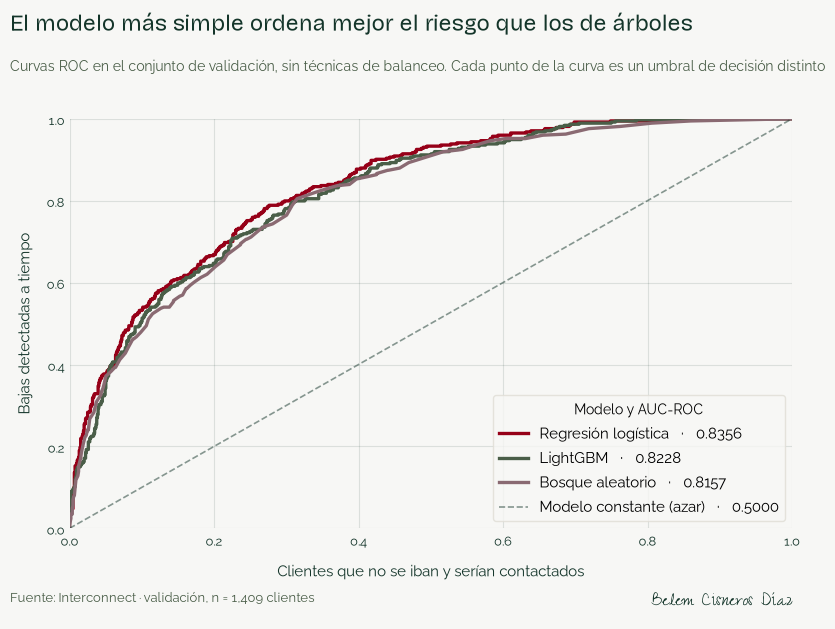

In [20]:
colores = {
    "fondo": "#F7F7F5",
    "logistica": "#960018",
    "lightgbm": "#4A5E48",
    "bosque": "#8A6A72",
    "azar": "#14352A",
    "texto": "#14352A",
}
fuente_titulo = "Bricolage Grotesque"
fuente_cuerpo = "Raleway"
fuente_firma = "Zeyada"

trazos = {
    "Regresión logística": colores["logistica"],
    "LightGBM": colores["lightgbm"],
    "Bosque aleatorio": colores["bosque"],
}

fig, ax = plt.subplots(figsize=(8.5, 6.4))
fig.patch.set_facecolor(colores["fondo"])
ax.set_facecolor(colores["fondo"])
fig.subplots_adjust(top=0.78, bottom=0.14, left=0.11, right=0.96)

for nombre, color in trazos.items():
    falsos, verdaderos, _ = roc_curve(y_validacion, probabilidades_baseline[nombre])
    area = roc_auc_score(y_validacion, probabilidades_baseline[nombre])
    ax.plot(falsos, verdaderos, color=color, linewidth=2.4, label=f"{nombre}   ·   {area:.4f}")

ax.plot([0, 1], [0, 1], color=colores["azar"], linestyle="--", linewidth=1.2, alpha=0.5,
        label="Modelo constante (azar)   ·   0.5000")

ax.set_xlabel("Clientes que no se iban y serían contactados", fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"], labelpad=10)
ax.set_ylabel("Bajas detectadas a tiempo", fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"], labelpad=10)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.tick_params(labelsize=9.5, colors=colores["texto"], length=0)
for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
    etiqueta.set_fontfamily(fuente_cuerpo)
ax.grid(color=colores["azar"], alpha=0.12, linewidth=0.8)
for lado in ax.spines.values():
    lado.set_visible(False)

leyenda = ax.legend(loc="lower right", frameon=True, fontsize=10.5, title="Modelo y AUC-ROC")
leyenda.get_frame().set_facecolor(colores["fondo"])
leyenda.get_frame().set_edgecolor("#E0DDD5")
leyenda.get_title().set_fontfamily(fuente_cuerpo)
for texto in leyenda.get_texts():
    texto.set_fontfamily(fuente_cuerpo)

fig.text(0.04, 0.95, "El modelo más simple ordena mejor el riesgo que los de árboles",
         fontsize=16, fontfamily=fuente_titulo, color=colores["texto"], ha="left", va="top")
fig.text(0.04, 0.875,
         "Curvas ROC en el conjunto de validación, sin técnicas de balanceo. Cada punto de la curva es un umbral de decisión distinto",
         fontsize=10, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left", va="top")
fig.text(0.04, 0.025, f"Fuente: Interconnect · validación, n = {len(y_validacion):,} clientes",
         fontsize=9, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left")
fig.text(0.96, 0.02, "Belem Cisneros Díaz", fontsize=15, fontfamily=fuente_firma, color=colores["texto"], ha="right")

fig.savefig(RUTA_FIGURAS / "baseline_curvas_roc.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

### 4. Optimización y manejo del desbalance

#### 4.1 Tres formas de tratar el desbalance

El desbalance de este proyecto es que solo el 26.5 % de los clientes se da de baja. Un modelo entrenado sin corregirlo aprende que equivocarse con la clase minoritaria sale barato, porque puede acertar mucho ignorándola. Comparo tres tratamientos sobre el mismo modelo, la regresión logística que ganó el baseline, para aislar el efecto de la técnica:

| Tratamiento | En qué consiste |
|---|---|
| Sin tratamiento | El modelo se entrena tal cual, con la proporción real |
| **Ajuste de pesos** (`class_weight="balanced"`) | Cada error sobre un cliente que se da de baja pesa más en la función que el modelo minimiza, en proporción inversa a la frecuencia de su clase |
| **Sobremuestreo** (*upsampling*) | Se repiten al azar, con reemplazo, registros de la clase minoritaria hasta igualar a la mayoritaria |

Los tres los aplico **únicamente sobre el conjunto de entrenamiento**. Validación y prueba conservan la proporción real del 26.5 %, porque son mi simulación de los clientes que el modelo encontrará en producción: equilibrarlas me daría cifras infladas que no se cumplirían nunca.

In [21]:
entrenamiento_con_objetivo = X_entrenamiento.copy()
entrenamiento_con_objetivo["se_dio_de_baja"] = y_entrenamiento

mayoritaria = entrenamiento_con_objetivo[entrenamiento_con_objetivo["se_dio_de_baja"] == 0]
minoritaria = entrenamiento_con_objetivo[entrenamiento_con_objetivo["se_dio_de_baja"] == 1]
minoritaria_ampliada = resample(
    minoritaria, replace=True, n_samples=len(mayoritaria), random_state=RANDOM_STATE
)
entrenamiento_balanceado = pd.concat([mayoritaria, minoritaria_ampliada]).sample(
    frac=1, random_state=RANDOM_STATE
)

X_balanceado = entrenamiento_balanceado.drop(columns=["se_dio_de_baja"])
y_balanceado = entrenamiento_balanceado["se_dio_de_baja"]

tratamientos = []

sin_tratamiento = Pipeline(
    [("preprocesamiento", preprocesador_lineal),
     ("modelo", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]
).fit(X_entrenamiento, y_entrenamiento)
tratamientos.append(evaluar("Sin tratamiento", sin_tratamiento, X_validacion, y_validacion))

con_pesos = Pipeline(
    [("preprocesamiento", preprocesador_lineal),
     ("modelo", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight="balanced"))]
).fit(X_entrenamiento, y_entrenamiento)
tratamientos.append(evaluar("Ajuste de pesos", con_pesos, X_validacion, y_validacion))

con_sobremuestreo = Pipeline(
    [("preprocesamiento", preprocesador_lineal),
     ("modelo", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]
).fit(X_balanceado, y_balanceado)
tratamientos.append(evaluar("Sobremuestreo", con_sobremuestreo, X_validacion, y_validacion))

print("Clientes en entrenamiento original:     ", len(y_entrenamiento), f"({y_entrenamiento.mean():.1%} de bajas)")
print("Clientes en entrenamiento sobremuestreado:", len(y_balanceado), f"({y_balanceado.mean():.1%} de bajas)")
print("Proporción real conservada en validación:", f"{y_validacion.mean():.1%} de bajas")

formatear(pd.DataFrame(tratamientos))

Clientes en entrenamiento original:      4225 (26.5% de bajas)
Clientes en entrenamiento sobremuestreado: 6208 (50.0% de bajas)
Proporción real conservada en validación: 26.5% de bajas


,modelo,AUC-ROC,Recall,Precisión
0,Sin tratamiento,0.8356,0.5749,0.6305
1,Ajuste de pesos,0.8354,0.8075,0.4855
2,Sobremuestreo,0.8344,0.8075,0.4903


**Lo que me reveló la comparación.** El AUC-ROC apenas se mueve entre los tres tratamientos —0.8356, 0.8354 y 0.8344— mientras que el Recall salta de 0.5749 a 0.8075 y la precisión cae de 0.6305 a cerca de 0.49.

No es una contradicción, y entenderla me ordenó el resto del proyecto. El AUC-ROC evalúa la capacidad de **ordenar** a los clientes por riesgo, y esa capacidad es independiente del umbral que se use para decidir. Equilibrar las clases no le enseña al modelo nada nuevo sobre quién se va: lo que hace es desplazar el punto donde el umbral predeterminado de 0.5 corta esa lista. Al correrlo hacia abajo, el modelo señala a más clientes, alcanza a más bajas (sube el Recall) y se equivoca más veces con quien no pensaba irse (baja la precisión).

De ahí saco dos conclusiones. La primera: entre ajuste de pesos y sobremuestreo me quedo con el **ajuste de pesos**, porque da prácticamente el mismo resultado sin duplicar 1 983 filas artificiales, sin alargar el entrenamiento y sin el riesgo de sobreajuste que implica repetir los mismos clientes. La segunda: si el tratamiento del desbalance es en realidad una decisión sobre el umbral, entonces ese umbral debe elegirse con un criterio de negocio y no por costumbre. Es lo que hago en la sección 5.4, calculando el valor neto esperado de cada umbral posible.

#### 4.2 Búsqueda de hiperparámetros

Llamo **hiperparámetros** a los ajustes que se fijan antes de entrenar y que el modelo no aprende solo: cuánta regularización aplicar, cuántos árboles construir, qué profundidad permitirles. Los busco con `RandomizedSearchCV`, que muestrea combinaciones al azar dentro de rangos que yo defino. Preferí este método a `GridSearchCV`, que prueba todas las combinaciones de una rejilla fija: con cinco o seis hiperparámetros por modelo, la rejilla completa son miles de ajustes y la búsqueda aleatoria encuentra resultados equivalentes explorando una fracción.

Tomé tres decisiones que sostienen esta búsqueda:

- **`scoring="roc_auc"`**, porque es la métrica con la que se decide. Optimizar una distinta de la que toma la decisión sería trabajar contra el propio criterio.
- **Validación cruzada estratificada de cinco particiones sobre el entrenamiento.** El conjunto de entrenamiento se parte en cinco; el modelo se entrena con cuatro y se evalúa en la quinta, rotando. Así cada combinación se juzga con cinco mediciones en lugar de una sola, y el conjunto de validación no participa: lo mantengo limpio para la comparación final entre modelos.
- **`class_weight` dentro del espacio de búsqueda**, para que la propia búsqueda decida si conviene el ajuste de pesos en cada familia de modelos.

In [22]:
validacion_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

espacios = {
    "Regresión logística": (
        Pipeline([("preprocesamiento", preprocesador_lineal),
                  ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
        {
            "modelo__C": loguniform(1e-3, 1e2),
            "modelo__class_weight": [None, "balanced"],
            "modelo__solver": ["lbfgs", "liblinear"],
        },
    ),
    "Bosque aleatorio": (
        Pipeline([("preprocesamiento", preprocesador_arboles),
                  ("modelo", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
        {
            "modelo__n_estimators": randint(200, 800),
            "modelo__max_depth": randint(3, 16),
            "modelo__min_samples_leaf": randint(1, 40),
            "modelo__max_features": uniform(0.2, 0.8),
            "modelo__class_weight": [None, "balanced"],
        },
    ),
    "LightGBM": (
        Pipeline([("preprocesamiento", preprocesador_arboles),
                  ("modelo", lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1))]),
        {
            "modelo__n_estimators": randint(100, 700),
            "modelo__learning_rate": loguniform(0.01, 0.3),
            "modelo__num_leaves": randint(5, 60),
            "modelo__min_child_samples": randint(10, 120),
            "modelo__reg_lambda": loguniform(1e-3, 20),
            "modelo__class_weight": [None, "balanced"],
        },
    ),
}

modelos_optimizados = {}
resultados_optimizados = []
hiperparametros_elegidos = {}

for nombre, (plantilla, espacio) in espacios.items():
    busqueda = RandomizedSearchCV(
        plantilla, espacio, n_iter=40, scoring="roc_auc",
        cv=validacion_cruzada, random_state=RANDOM_STATE, n_jobs=-1,
    )
    busqueda.fit(X_entrenamiento, y_entrenamiento)
    modelos_optimizados[nombre] = busqueda.best_estimator_
    hiperparametros_elegidos[nombre] = {
        clave.replace("modelo__", ""): (float(round(valor, 4)) if isinstance(valor, float) else valor)
        for clave, valor in busqueda.best_params_.items()
    }
    fila = evaluar(nombre, busqueda.best_estimator_, X_validacion, y_validacion)
    fila["AUC-ROC en validación cruzada"] = busqueda.best_score_
    resultados_optimizados.append(fila)

for nombre, parametros in hiperparametros_elegidos.items():
    print(f"{nombre}: {parametros}")

formatear(pd.DataFrame(resultados_optimizados), indice="modelo")

Regresión logística: {'C': 1.6307, 'class_weight': None, 'solver': 'liblinear'}
Bosque aleatorio: {'class_weight': 'balanced', 'max_depth': 13, 'max_features': 0.3566, 'min_samples_leaf': 31, 'n_estimators': 321}
LightGBM: {'class_weight': 'balanced', 'learning_rate': 0.0107, 'min_child_samples': 11, 'n_estimators': 637, 'num_leaves': 5, 'reg_lambda': 0.0304}


,AUC-ROC,Recall,Precisión,AUC-ROC en validación cruzada
modelo,,,,
Regresión logística,0.8356,0.5749,0.6324,0.8485
Bosque aleatorio,0.8365,0.7968,0.4958,0.8497
LightGBM,0.8374,0.8021,0.4910,0.8506


#### 4.3 Elección del modelo final

Antes de decidir quise cerrar una pregunta pendiente: ¿convendría construir más variables derivadas? Probé tres —el número de servicios contratados, la diferencia entre el cargo actual y el cargo promedio histórico del cliente, y la antigüedad agrupada en tramos, que le permitiría al modelo lineal capturar la curva no lineal que mostró el EDA—. Las comparo con validación cruzada sobre el entrenamiento, que da una estimación más estable que una sola medición, y reporto la desviación típica entre particiones junto a la media. Mi criterio es que si la mejora resulta menor que esa variabilidad, no es una mejora sino ruido.

Con ese resultado en la mano decido entre cinco candidatos. Mi criterio no es el AUC-ROC más alto en el tercer decimal, porque las diferencias entre modelos optimizados son mucho menores que la variabilidad de la propia medición. Cuando dos modelos empatan dentro del margen de error, elegir el más complejo solo por un decimal sería confundir ruido con desempeño.

In [23]:
OPCIONES_DE_SERVICIO = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "MultipleLines",
]

X_ampliado = X.copy()
X_ampliado["servicios_contratados"] = (datos[OPCIONES_DE_SERVICIO] == "Yes").sum(axis=1).astype("int8")
cargo_historico = np.where(
    datos["antiguedad_meses"] > 0,
    datos["TotalCharges"] / datos["antiguedad_meses"].clip(lower=1),
    datos["MonthlyCharges"],
)
X_ampliado["cambio_de_cargo"] = (datos["MonthlyCharges"] - cargo_historico).round(2)
X_ampliado["antiguedad_tramo"] = pd.cut(
    datos["antiguedad_meses"], [-1, 2, 5, 11, 23, 47, 1000],
    labels=["Menos de 3", "3 a 5", "6 a 11", "12 a 23", "24 a 47", "48 o más"],
).astype(str)

X_ampliado_entrenamiento = X_ampliado.loc[X_entrenamiento.index]
NUMERICAS_AMPLIADAS = COLUMNAS_NUMERICAS + ["servicios_contratados", "cambio_de_cargo"]
CATEGORICAS_AMPLIADAS = COLUMNAS_CATEGORICAS + ["antiguedad_tramo"]

comparacion_variables = []
for nombre, caracteristicas, numericas, categoricas in [
    ("Conjunto actual", X_entrenamiento, COLUMNAS_NUMERICAS, COLUMNAS_CATEGORICAS),
    ("Con variables derivadas", X_ampliado_entrenamiento, NUMERICAS_AMPLIADAS, CATEGORICAS_AMPLIADAS),
]:
    tuberia = Pipeline(
        [
            ("preprocesamiento", ColumnTransformer([
                ("categoricas", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), categoricas),
                ("numericas", StandardScaler(), numericas),
            ])),
            ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                          C=1.6307, solver="liblinear", class_weight="balanced")),
        ]
    )
    puntajes = cross_val_score(tuberia, caracteristicas, y_entrenamiento, scoring="roc_auc", cv=validacion_cruzada, n_jobs=-1)
    comparacion_variables.append({
        "conjunto de variables": nombre,
        "variables": len(numericas) + len(categoricas),
        "AUC-ROC (media)": puntajes.mean(),
        "desviación entre particiones": puntajes.std(),
    })

formatear(
    pd.DataFrame(comparacion_variables),
    formatos={"AUC-ROC (media)": "{:.4f}", "desviación entre particiones": "± {:.4f}"},
    indice="conjunto de variables",
)

,variables,AUC-ROC (media),desviación entre particiones
conjunto de variables,,,
Conjunto actual,19,0.8481,± 0.0163
Con variables derivadas,22,0.8513,± 0.0141


La mejora al añadir tres variables es de 0.0032, cinco veces menor que la desviación de 0.0163 entre particiones. No la considero una mejora real. Me quedo con el conjunto de 19 variables: igual de bueno y más simple de explicar y de mantener.

Paso entonces a la comparación final de candidatos sobre el conjunto de validación.

In [24]:
logistica_final = Pipeline(
    [("preprocesamiento", preprocesador_lineal),
     ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                   C=1.6307, solver="liblinear", class_weight="balanced"))]
).fit(X_entrenamiento, y_entrenamiento)

candidatos = [
    evaluar("Regresión logística · baseline", modelos_baseline["Regresión logística"], X_validacion, y_validacion),
    evaluar("Regresión logística · optimizada", modelos_optimizados["Regresión logística"], X_validacion, y_validacion),
    evaluar("Regresión logística · optimizada con ajuste de pesos", logistica_final, X_validacion, y_validacion),
    evaluar("Bosque aleatorio · optimizado", modelos_optimizados["Bosque aleatorio"], X_validacion, y_validacion),
    evaluar("LightGBM · optimizado", modelos_optimizados["LightGBM"], X_validacion, y_validacion),
]

hiperparametros_por_candidato = {
    "Regresión logística · baseline": {"C": 1.0, "solver": "lbfgs", "class_weight": None},
    "Regresión logística · optimizada": hiperparametros_elegidos["Regresión logística"],
    "Regresión logística · optimizada con ajuste de pesos": {
        **hiperparametros_elegidos["Regresión logística"], "class_weight": "balanced"
    },
    "Bosque aleatorio · optimizado": hiperparametros_elegidos["Bosque aleatorio"],
    "LightGBM · optimizado": hiperparametros_elegidos["LightGBM"],
}

metricas["optimizados"] = {
    fila["modelo"]: {
        "auc_roc_validacion": round(fila["AUC-ROC"], 4),
        "recall_validacion": round(fila["Recall"], 4),
        "precision_validacion": round(fila["Precisión"], 4),
        "hiperparametros": hiperparametros_por_candidato[fila["modelo"]],
    }
    for fila in candidatos
}

formatear(pd.DataFrame(candidatos), indice="modelo")

,AUC-ROC,Recall,Precisión
modelo,,,
Regresión logística · baseline,0.8356,0.5749,0.6305
Regresión logística · optimizada,0.8356,0.5749,0.6324
Regresión logística · optimizada con ajuste de pesos,0.8354,0.8075,0.4855
Bosque aleatorio · optimizado,0.8365,0.7968,0.4958
LightGBM · optimizado,0.8374,0.8021,0.4910


**El modelo que elijo es la regresión logística optimizada con ajuste de pesos.** Lo sostengo con cuatro razones:

1. **Empata en la métrica principal.** Su AUC-ROC en validación es 0.8354 frente a 0.8374 de LightGBM: una diferencia de 0.0020, cuando la variabilidad que yo misma medí entre particiones de la validación cruzada es de 0.0163. Lo considero un empate técnico.
2. **Gana en la métrica que importa para el negocio.** Su Recall de 0.8075 es el más alto de los cinco candidatos, por encima de 0.8021 de LightGBM y de 0.7968 del bosque aleatorio.
3. **Lo puedo explicar.** Es un modelo lineal: cada coeficiente indica en qué dirección y con qué fuerza empuja una variable, de modo que el equipo de marketing puede leer por qué el modelo señaló a un cliente. Un conjunto de 637 árboles no ofrece eso.
4. **Es más barato de operar.** Entrena en segundos, pesa poco y no requiere mantener una librería de *gradient boosting* en producción.

Elijo un modelo simple y bien justificado por encima de uno complejo que no aporta una ventaja demostrable.

#### 4.4 Evaluación en el conjunto de prueba

Este es el único momento del proyecto en que abro el conjunto de prueba, con el modelo ya elegido y sin posibilidad de volver atrás. Si estas cifras no me gustaran, no podría cambiar el modelo y volver a medir: eso convertiría la prueba en un segundo conjunto de validación y la estimación dejaría de ser honesta.

Reporto la matriz de confusión en lenguaje de negocio, porque cada una de sus cuatro celdas tiene un costo distinto para Interconnect y es ahí donde el modelo se vuelve una decisión y no un número.

In [25]:
resultado_prueba = evaluar("Modelo final en prueba", logistica_final, X_prueba, y_prueba)
probabilidades_prueba = logistica_final.predict_proba(X_prueba)[:, 1]
predicciones_prueba = logistica_final.predict(X_prueba)
matriz = confusion_matrix(y_prueba, predicciones_prueba)
verdaderos_negativos, falsos_positivos, falsos_negativos, verdaderos_positivos = matriz.ravel()

if resultado_prueba["AUC-ROC"] >= 0.88:
    calificacion = "Sobresaliente"
elif resultado_prueba["AUC-ROC"] >= 0.87:
    calificacion = "Excelente"
elif resultado_prueba["AUC-ROC"] >= 0.85:
    calificacion = "Muy bueno"
elif resultado_prueba["AUC-ROC"] >= 0.81:
    calificacion = "Bueno"
elif resultado_prueba["AUC-ROC"] >= 0.75:
    calificacion = "Aprobado"
else:
    calificacion = "No aprobado"

metricas["final"] = {
    "modelo": "Regresión logística optimizada con ajuste de pesos",
    "hiperparametros": {"C": 1.6307, "solver": "liblinear", "class_weight": "balanced"},
    "umbral": 0.5,
    "auc_roc_prueba": round(resultado_prueba["AUC-ROC"], 4),
    "recall_prueba": round(resultado_prueba["Recall"], 4),
    "precision_prueba": round(resultado_prueba["Precisión"], 4),
    "calificacion_segun_la_escala": calificacion,
    "matriz_de_confusion": {
        "verdaderos_negativos": int(verdaderos_negativos),
        "falsos_positivos": int(falsos_positivos),
        "falsos_negativos": int(falsos_negativos),
        "verdaderos_positivos": int(verdaderos_positivos),
    },
}

print(f"AUC-ROC en prueba: {resultado_prueba['AUC-ROC']:.4f}  ·  escala del enunciado: {calificacion}")
print(f"Recall en prueba:  {resultado_prueba['Recall']:.4f}")
print(f"Precisión en prueba: {resultado_prueba['Precisión']:.4f}")
print(f"\nDe las {int(y_prueba.sum())} bajas reales del conjunto de prueba, el modelo detectó {int(verdaderos_positivos)} y dejó escapar {int(falsos_negativos)}.")

formatear(pd.DataFrame([resultado_prueba]), indice="modelo")

AUC-ROC en prueba: 0.8421  ·  escala del enunciado: Bueno
Recall en prueba:  0.7968
Precisión en prueba: 0.5256

De las 374 bajas reales del conjunto de prueba, el modelo detectó 298 y dejó escapar 76.


,AUC-ROC,Recall,Precisión
modelo,,,
Modelo final en prueba,0.8421,0.7968,0.5256


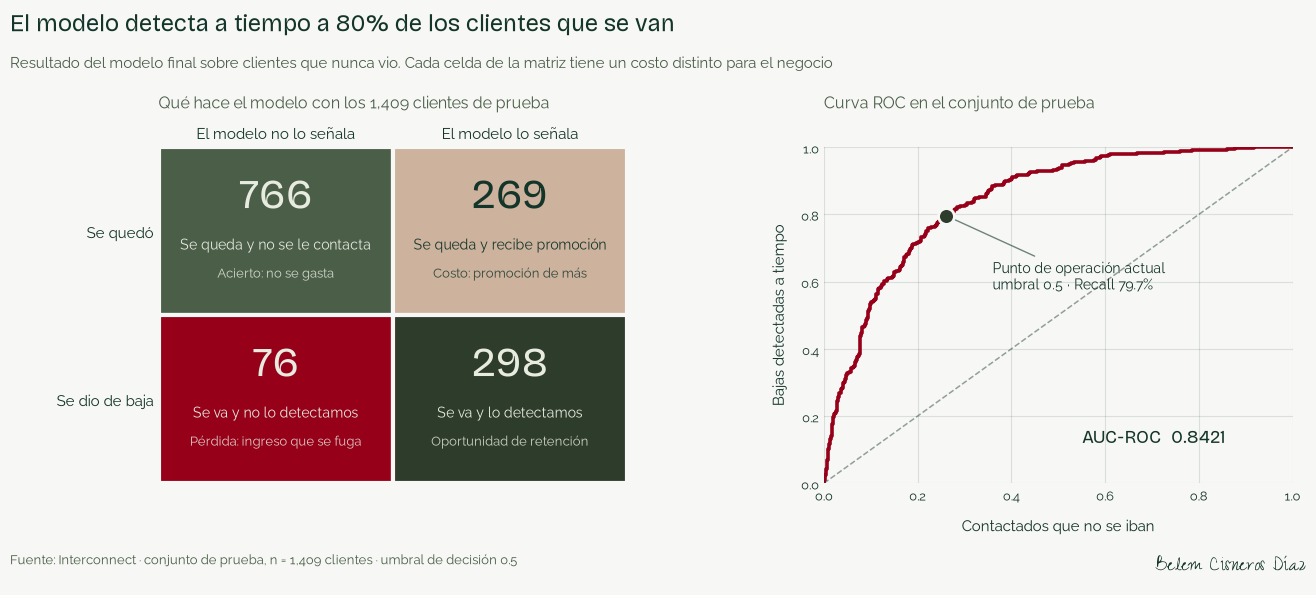

In [26]:
colores = {
    "fondo": "#F7F7F5", "acierto": "#4A5E48", "acierto_fuerte": "#2E3C2C",
    "costo": "#CDB29D", "perdida": "#960018", "texto": "#14352A",
    "claro": "#E8EBE0", "referencia": "#8A6A72",
}
fuente_titulo = "Bricolage Grotesque"
fuente_cuerpo = "Raleway"
fuente_firma = "Zeyada"

fig, (izquierda, derecha) = plt.subplots(1, 2, figsize=(13.5, 6))
fig.patch.set_facecolor(colores["fondo"])
fig.subplots_adjust(top=0.73, bottom=0.17, left=0.13, right=0.97, wspace=0.42)

celdas = [
    (0, 0, int(verdaderos_negativos), colores["acierto"], "Se queda y no se le contacta", "Acierto: no se gasta"),
    (0, 1, int(falsos_positivos), colores["costo"], "Se queda y recibe promoción", "Costo: promoción de más"),
    (1, 0, int(falsos_negativos), colores["perdida"], "Se va y no lo detectamos", "Pérdida: ingreso que se fuga"),
    (1, 1, int(verdaderos_positivos), colores["acierto_fuerte"], "Se va y lo detectamos", "Oportunidad de retención"),
]
for fila, columna, valor, color, descripcion, consecuencia in celdas:
    izquierda.add_patch(plt.Rectangle((columna, 1 - fila), 1, 1, facecolor=color, edgecolor=colores["fondo"], linewidth=3))
    tono = colores["texto"] if color == colores["costo"] else colores["claro"]
    izquierda.text(columna + 0.5, 1.72 - fila, f"{valor:,}", ha="center", va="center", fontsize=30, fontfamily=fuente_titulo, color=tono)
    izquierda.text(columna + 0.5, 1.42 - fila, descripcion, ha="center", va="center", fontsize=10, fontfamily=fuente_cuerpo, color=tono)
    izquierda.text(columna + 0.5, 1.25 - fila, consecuencia, ha="center", va="center", fontsize=9, fontfamily=fuente_cuerpo, color=tono, alpha=0.85)

izquierda.set_xlim(0, 2)
izquierda.set_ylim(0, 2)
izquierda.set_xticks([0.5, 1.5])
izquierda.set_yticks([1.5, 0.5])
izquierda.set_xticklabels(["El modelo no lo señala", "El modelo lo señala"], fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"])
izquierda.set_yticklabels(["Se quedó", "Se dio de baja"], fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"])
izquierda.xaxis.set_ticks_position("top")
izquierda.tick_params(length=0)
for lado in izquierda.spines.values():
    lado.set_visible(False)
izquierda.set_title("Qué hace el modelo con los 1,409 clientes de prueba", fontsize=11.5, fontfamily=fuente_cuerpo, color="#4A5E48", loc="left", pad=28)

falsos, verdaderos, _ = roc_curve(y_prueba, probabilidades_prueba)
derecha.set_facecolor(colores["fondo"])
derecha.plot(falsos, verdaderos, color=colores["perdida"], linewidth=2.6)
derecha.plot([0, 1], [0, 1], color=colores["texto"], linestyle="--", linewidth=1.1, alpha=0.45)
punto_x = falsos_positivos / (falsos_positivos + verdaderos_negativos)
punto_y = verdaderos_positivos / (verdaderos_positivos + falsos_negativos)
derecha.scatter([punto_x], [punto_y], s=130, color=colores["acierto_fuerte"], zorder=5, edgecolor=colores["fondo"], linewidth=2)
derecha.annotate(
    f"Punto de operación actual\numbral 0.5 · Recall {punto_y:.1%}",
    xy=(punto_x, punto_y), xytext=(punto_x + 0.10, punto_y - 0.22),
    fontsize=10, fontfamily=fuente_cuerpo, color=colores["texto"],
    arrowprops={"arrowstyle": "-", "color": colores["texto"], "alpha": 0.6},
)
derecha.text(0.55, 0.12, f"AUC-ROC  {resultado_prueba['AUC-ROC']:.4f}", fontsize=13, fontfamily=fuente_titulo, color=colores["texto"])
derecha.set_xlabel("Contactados que no se iban", fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"], labelpad=10)
derecha.set_ylabel("Bajas detectadas a tiempo", fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"], labelpad=10)
derecha.set_xlim(0, 1)
derecha.set_ylim(0, 1)
derecha.tick_params(labelsize=9.5, colors=colores["texto"], length=0)
for etiqueta in derecha.get_xticklabels() + derecha.get_yticklabels():
    etiqueta.set_fontfamily(fuente_cuerpo)
derecha.grid(color=colores["texto"], alpha=0.12, linewidth=0.8)
for lado in derecha.spines.values():
    lado.set_visible(False)
derecha.set_title("Curva ROC en el conjunto de prueba", fontsize=11.5, fontfamily=fuente_cuerpo, color="#4A5E48", loc="left", pad=28)

fig.text(0.02, 0.96, f"El modelo detecta a tiempo a {punto_y:.0%} de los clientes que se van",
         fontsize=17, fontfamily=fuente_titulo, color=colores["texto"], ha="left", va="top")
fig.text(0.02, 0.885,
         "Resultado del modelo final sobre clientes que nunca vio. Cada celda de la matriz tiene un costo distinto para el negocio",
         fontsize=10.5, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left", va="top")
fig.text(0.02, 0.035, f"Fuente: Interconnect · conjunto de prueba, n = {len(y_prueba):,} clientes · umbral de decisión 0.5",
         fontsize=9, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left")
fig.text(0.98, 0.025, "Belem Cisneros Díaz", fontsize=16, fontfamily=fuente_firma, color=colores["texto"], ha="right")

fig.savefig(RUTA_FIGURAS / "final_matriz_y_roc_prueba.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

#### 4.5 Qué variables mueven el riesgo

Mido la importancia de cada variable por **permutación**: se desordenan al azar los valores de una sola columna y se observa cuánto cae el AUC-ROC. Si al romper la relación entre esa variable y la realidad el modelo empeora mucho, la variable importaba; si no cambia nada, no aportaba. Repito el proceso diez veces por variable y reporto la caída media junto con su dispersión.

Elegí este método en lugar de leer directamente los coeficientes del modelo lineal por dos razones. La primera es que mide el efecto sobre el desempeño real y no sobre la fórmula interna. La segunda es que funciona igual para cualquier modelo, de manera que si en el futuro se cambia la regresión logística por otro algoritmo, la comparación sigue siendo válida.

Lo calculo sobre el conjunto de **validación** y no sobre el de entrenamiento, porque lo que me interesa es qué variables ayudan a acertar con clientes que el modelo no ha visto, no cuáles usó para memorizar los que ya conocía.

In [27]:
importancia = permutation_importance(
    logistica_final, X_validacion, y_validacion,
    scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)

importancias = pd.DataFrame(
    {
        "variable": X_validacion.columns,
        "caída del AUC-ROC": importancia.importances_mean,
        "dispersión": importancia.importances_std,
    }
).sort_values("caída del AUC-ROC", ascending=False).reset_index(drop=True)

metricas["importancia_por_permutacion"] = {
    fila["variable"]: round(float(fila["caída del AUC-ROC"]), 5)
    for _, fila in importancias.iterrows()
}

formatear(
    importancias.head(10),
    formatos={"caída del AUC-ROC": "{:.5f}", "dispersión": "± {:.5f}"},
    indice="variable",
)

,caída del AUC-ROC,dispersión
variable,,
antiguedad_meses,0.16966,± 0.01028
InternetService,0.04167,± 0.00732
Type,0.03420,± 0.00511
MonthlyCharges,0.03296,± 0.00496
TotalCharges,0.01550,± 0.00383
StreamingTV,0.00512,± 0.00189
OnlineSecurity,0.00378,± 0.00097
PaymentMethod,0.00370,± 0.00234
MultipleLines,0.00319,± 0.00121


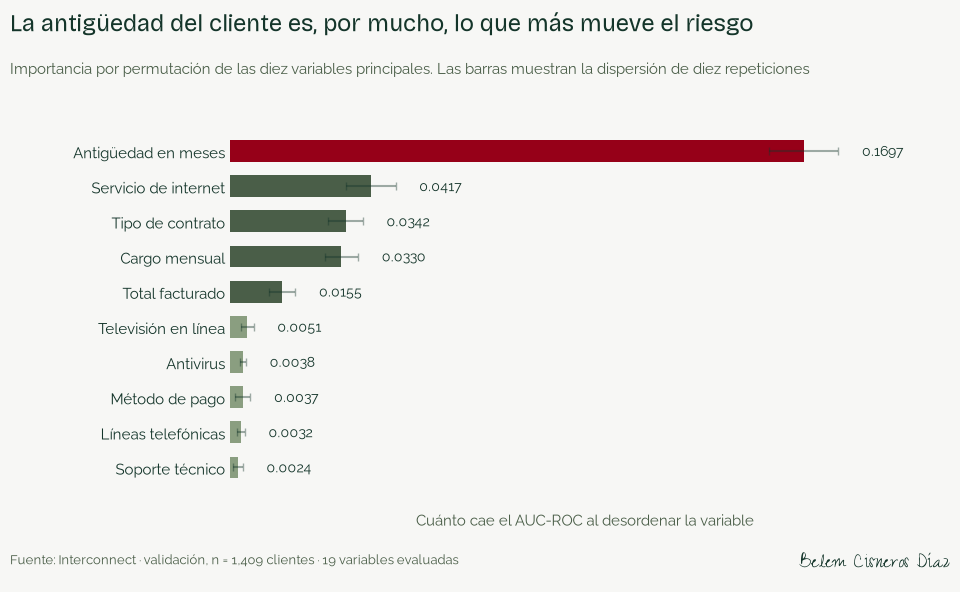

In [28]:
colores = {"fondo": "#F7F7F5", "alta": "#960018", "media": "#4A5E48", "baja": "#8A9E80", "texto": "#14352A"}
fuente_titulo = "Bricolage Grotesque"
fuente_cuerpo = "Raleway"
fuente_firma = "Zeyada"

NOMBRES_LEGIBLES = {
    "antiguedad_meses": "Antigüedad en meses",
    "InternetService": "Servicio de internet",
    "Type": "Tipo de contrato",
    "MonthlyCharges": "Cargo mensual",
    "TotalCharges": "Total facturado",
    "StreamingTV": "Televisión en línea",
    "OnlineSecurity": "Antivirus",
    "PaymentMethod": "Método de pago",
    "MultipleLines": "Líneas telefónicas",
    "TechSupport": "Soporte técnico",
}

principales = importancias.head(10).iloc[::-1]
etiquetas = [NOMBRES_LEGIBLES.get(v, v) for v in principales["variable"]]

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(colores["fondo"])
ax.set_facecolor(colores["fondo"])
fig.subplots_adjust(top=0.76, bottom=0.14, left=0.24, right=0.95)

tonos = [
    colores["alta"] if v > 0.05 else colores["media"] if v > 0.01 else colores["baja"]
    for v in principales["caída del AUC-ROC"]
]
barras = ax.barh(etiquetas, principales["caída del AUC-ROC"], height=0.62, color=tonos,
                 xerr=principales["dispersión"], error_kw={"ecolor": colores["texto"], "alpha": 0.4, "capsize": 3})

for barra, valor, dispersion in zip(barras, principales["caída del AUC-ROC"], principales["dispersión"]):
    ax.text(valor + dispersion + 0.007, barra.get_y() + barra.get_height() / 2, f"{valor:.4f}",
            va="center", ha="left", fontsize=10, fontfamily=fuente_cuerpo, color=colores["texto"])

ax.set_xlim(0, 0.21)
ax.set_xticks([])
ax.tick_params(axis="y", length=0, labelsize=11)
for etiqueta in ax.get_yticklabels():
    etiqueta.set_fontfamily(fuente_cuerpo)
    etiqueta.set_color(colores["texto"])
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_xlabel("Cuánto cae el AUC-ROC al desordenar la variable", fontsize=10.5, fontfamily=fuente_cuerpo, color="#4A5E48", labelpad=12)

fig.text(0.02, 0.95, "La antigüedad del cliente es, por mucho, lo que más mueve el riesgo",
         fontsize=17, fontfamily=fuente_titulo, color=colores["texto"], ha="left", va="top")
fig.text(0.02, 0.865,
         "Importancia por permutación de las diez variables principales. Las barras muestran la dispersión de diez repeticiones",
         fontsize=10.5, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left", va="top")
fig.text(0.02, 0.025, f"Fuente: Interconnect · validación, n = {len(y_validacion):,} clientes · 19 variables evaluadas",
         fontsize=9, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left")
fig.text(0.96, 0.02, "Belem Cisneros Díaz", fontsize=16, fontfamily=fuente_firma, color=colores["texto"], ha="right")

fig.savefig(RUTA_FIGURAS / "final_importancia_variables.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

Todas las cifras que reporto se van acumulando en el diccionario `metricas`, que al cerrar el notebook se guarda en `resultados/metricas.json`. Ese archivo es mi fuente única de números: cualquier documento que acompañe a este trabajo lee de él en lugar de copiar cifras a mano, que es como aparecen las inconsistencias entre documentos.

### 5. Valor de negocio

Construí esta sección porque considero que un modelo no es un entregable en sí mismo, sino un insumo para decidir. Aquí traduzco el AUC-ROC y el Recall a las tres preguntas que, en mi lectura, el equipo de marketing necesita responder antes de aprobar un presupuesto: cuánto dinero está en juego, a cuántos clientes conviene contactar y qué pasa si no se hace nada.

Separo con claridad dos tipos de cifra. Las que salen de los datos —cargos mensuales, antigüedad, tasas observadas— las calculo y las reporto como **datos**. Las que Interconnect no proporciona —el costo de una promoción, la proporción de clientes que aceptan una oferta, cuántos meses extra permanece quien acepta— no puedo inventarlas: las trato como **supuestos declarados** y presento varios escenarios en lugar de un número único. Mezclar ambas cosas sería presentar una estimación como si fuera una medición, y preferí no hacerlo.

Los montos van en la moneda de los datos de origen, sin convertir, porque la fuente no especifica cuál es.

#### 5.1 Contexto de mercado

Quise situar el problema antes de cuantificarlo. La fuga de clientes —**churn** en la literatura del sector, que es como aparece en las fuentes que cito— no es un problema particular de Interconnect: es el indicador que ordena la estrategia comercial de todo el sector. Estas cifras lo dimensionan y las tomé de fuentes verificadas, con enlace y fecha para que puedan comprobarse.

| Dato | Fuente |
|---|---|
| El churn de telefonía postpago de AT&T fue de 0.98 % en el cuarto trimestre de 2025, frente a 0.85 % un año antes | [PhoneArena, enero de 2026](https://www.phonearena.com/news/at-t-had-better-than-expected-quarter_id177767) |
| T-Mobile reportó 1.02 % en el cuarto trimestre de 2025 y 0.93 % en el año | [Converge Digest, 12 de febrero de 2026](https://convergedigest.com/t-mobile-extends-lead-in-postpaid-and-fwa-as-arpa-and-cash-flow-climb/) |
| Verizon perdió cerca de 2.25 millones de clientes postpago en tres años; su director general atribuyó la caída a un alza de 25 puntos base en el churn | [AOL Finance, 2 de febrero de 2026](https://www.aol.com/finance/verizon-ceo-hopes-drastic-changes-230300198.html) |
| Conseguir un cliente nuevo cuesta entre 5 y 25 veces más que retener uno; un aumento de 5 % en la retención se asocia con incrementos de 25 % a 95 % en las utilidades | [Gallo, A., Harvard Business Review, 29 de octubre de 2014](https://hbr.org/2014/10/the-value-of-keeping-the-right-customers) |
| Un enfoque analítico integral reduce el churn hasta 15 %; un operador lo redujo entre 10 % y 15 % en 18 meses combinando predicción, microsegmentos y una biblioteca de ofertas | [Jain y Surana, McKinsey, 12 de diciembre de 2017](https://www.mckinsey.com/industries/technology-media-and-telecommunications/our-insights/reducing-churn-in-telecom-through-advanced-analytics) |
| En México, la portabilidad móvil cayó 13.98 % anual en el segundo trimestre de 2026, con 3,049,174 líneas portadas sobre 157.1 millones de líneas activas en junio de 2026 | [Xataka México con datos de la CRT, 17 de agosto de 2026](https://www.xataka.com.mx/telecomunicaciones/registro-obligatorio-celulares-esta-cambiando-otro-habito-mexicanos-cada-vez-cambian-compania) |

Quiero advertir una diferencia de escala, porque sería fácil leer mal estas cifras. Los grandes operadores reportan churn **mensual** de alrededor del 1 %, mientras que el 26.5 % de este registro es una tasa **acumulada**: la proporción de clientes que se dieron de baja en toda la historia del archivo, no en un mes. No son cifras comparables entre sí y no las presento como si lo fueran. Lo que sí me parece comparable es la conclusión de McKinsey: un sistema de predicción con ofertas segmentadas reduce la fuga entre 10 % y 15 %, y es exactamente el sistema que propongo aquí.

#### 5.2 Cuánto dinero está en juego

Calculo dos cifras con el cargo mensual real de cada cliente. La primera mira hacia atrás: cuánto ingreso mensual representaban los clientes que ya se fueron. La segunda mira hacia adelante: cuánto ingreso mensual representa la lista de clientes que el modelo señalaría hoy.

In [29]:
ingreso_perdido = float(datos.loc[datos["se_dio_de_baja"] == 1, "MonthlyCharges"].sum())
ingreso_cartera = float(datos["MonthlyCharges"].sum())

prueba_con_riesgo = X_prueba.copy()
prueba_con_riesgo["se_dio_de_baja"] = y_prueba
prueba_con_riesgo["probabilidad_de_baja"] = probabilidades_prueba
prueba_con_riesgo["senalado"] = prueba_con_riesgo["probabilidad_de_baja"] >= 0.5

lista_de_contacto = prueba_con_riesgo[prueba_con_riesgo["senalado"]]
senalados_que_se_fueron = lista_de_contacto[lista_de_contacto["se_dio_de_baja"] == 1]
senalados_que_se_quedaron = lista_de_contacto[lista_de_contacto["se_dio_de_baja"] == 0]
escaparon = prueba_con_riesgo[(~prueba_con_riesgo["senalado"]) & (prueba_con_riesgo["se_dio_de_baja"] == 1)]

metricas["negocio"] = {
    "ingreso_mensual_perdido_por_bajas": round(ingreso_perdido, 2),
    "ingreso_mensual_de_la_cartera": round(ingreso_cartera, 2),
    "proporcion_del_ingreso_perdida": round(ingreso_perdido / ingreso_cartera, 4),
    "prueba": {
        "clientes_en_la_lista_de_contacto": int(len(lista_de_contacto)),
        "ingreso_mensual_de_la_lista": round(float(lista_de_contacto["MonthlyCharges"].sum()), 2),
        "ingreso_mensual_rescatable": round(float(senalados_que_se_fueron["MonthlyCharges"].sum()), 2),
        "ingreso_mensual_que_escapa": round(float(escaparon["MonthlyCharges"].sum()), 2),
    },
}

print("SOBRE TODO EL REGISTRO HISTÓRICO")
print(f"  Ingreso mensual de la cartera completa:        {ingreso_cartera:>12,.2f}")
print(f"  Ingreso mensual de los clientes que se fueron: {ingreso_perdido:>12,.2f}  ({ingreso_perdido / ingreso_cartera:.1%} del total)")
print()
print(f"SOBRE EL CONJUNTO DE PRUEBA ({len(prueba_con_riesgo):,} clientes que el modelo nunca vio)")
print(f"  La lista de contacto tiene {len(lista_de_contacto)} clientes y representa {lista_de_contacto['MonthlyCharges'].sum():,.2f} de ingreso mensual")
print(f"  De esa lista, {len(senalados_que_se_fueron)} sí se dieron de baja: {senalados_que_se_fueron['MonthlyCharges'].sum():,.2f} de ingreso mensual rescatable")
print(f"  Y {len(senalados_que_se_quedaron)} se habrían quedado de todos modos: ese es el costo de las promociones de más")
print(f"  Fuera de la lista escaparon {len(escaparon)} bajas: {escaparon['MonthlyCharges'].sum():,.2f} de ingreso mensual que se pierde sin aviso")

ingreso_en_fuga = float(senalados_que_se_fueron["MonthlyCharges"].sum() + escaparon["MonthlyCharges"].sum())
cobertura_de_ingreso = float(senalados_que_se_fueron["MonthlyCharges"].sum()) / ingreso_en_fuga
metricas["negocio"]["prueba"]["cobertura_del_ingreso_en_fuga"] = round(cobertura_de_ingreso, 4)

print()
print(f"  Cargo mensual promedio de las bajas detectadas: {senalados_que_se_fueron['MonthlyCharges'].mean():,.2f}")
print(f"  Cargo mensual promedio de las bajas que escapan: {escaparon['MonthlyCharges'].mean():,.2f}")
print(f"  El modelo alcanza el {cobertura_de_ingreso:.1%} del ingreso en fuga, frente al {resultado_prueba['Recall']:.1%} de los clientes")

SOBRE TODO EL REGISTRO HISTÓRICO
  Ingreso mensual de la cartera completa:          456,116.60
  Ingreso mensual de los clientes que se fueron:   139,130.85  (30.5% del total)

SOBRE EL CONJUNTO DE PRUEBA (1,409 clientes que el modelo nunca vio)
  La lista de contacto tiene 567 clientes y representa 42,549.40 de ingreso mensual
  De esa lista, 298 sí se dieron de baja: 22,497.70 de ingreso mensual rescatable
  Y 269 se habrían quedado de todos modos: ese es el costo de las promociones de más
  Fuera de la lista escaparon 76 bajas: 5,085.35 de ingreso mensual que se pierde sin aviso

  Cargo mensual promedio de las bajas detectadas: 75.50
  Cargo mensual promedio de las bajas que escapan: 66.91
  El modelo alcanza el 81.6% del ingreso en fuga, frente al 79.7% de los clientes


**Lo que encontré.** Los clientes que se dieron de baja representaban 139,130.85 de ingreso mensual, el 30.5 % de los 456,116.60 que suman los cargos mensuales de todo el registro. Quiero precisar ese denominador para que no se lea de más: incluye tanto a los clientes activos como a los que ya se fueron, de modo que la cifra mide el peso histórico de la fuga y no una pérdida que siga ocurriendo hoy. La cartera que permanece activa factura 316,985.75 mensuales. Aun así no es una fuga marginal: casi un tercio de la facturación registrada correspondía a clientes que terminaron yéndose.

Sobre el conjunto de prueba, que son clientes que el modelo nunca vio, y usando el umbral predeterminado de 0.50, la lista de contacto tendría 567 nombres y concentraría 42,549.40 de ingreso mensual. Aclaro el umbral porque en la sección 5.4 recomiendo operar con uno más exigente, 0.73, que reduce esa lista a 310 clientes: las cifras de este apartado describen lo que hace el modelo en su punto de operación predeterminado, no el tamaño de la campaña que propongo. De ese monto, 22,497.70 corresponden a clientes que efectivamente se iban —ingreso recuperable si la promoción funciona— y 20,051.70 a clientes que se habrían quedado de todos modos, que es el costo de las promociones de más. Fuera de la lista escapan 76 bajas con 5,085.35 de ingreso mensual.

Encontré además un detalle que mejora el resultado y que me parece importante señalar. Las bajas que el modelo no detecta tienen un cargo mensual promedio de 66.91, frente a 75.50 de las que sí detecta: son clientes de menor valor. En consecuencia el modelo alcanza el **81.6 % del ingreso mensual en fuga**, por encima del 79.7 % de los clientes. Para el negocio eso vale más que un Recall equivalente repartido al azar, porque prioriza donde está el dinero.

#### 5.3 A cuántos clientes conviene contactar

Partí de que marketing no puede contactar a toda la cartera. La pregunta operativa es entonces qué porcentaje de clientes hay que atender para capturar qué porcentaje de las bajas. Para responderla ordeno a los clientes de prueba de mayor a menor probabilidad estimada, los divido en diez grupos iguales —**deciles**— y calculo cuántas de las bajas reales caen en cada grupo acumulado.

Tomo el azar como punto de comparación: si Interconnect contactara clientes sin criterio, en el 10 % de la cartera encontraría el 10 % de las bajas. La distancia entre la curva del modelo y esa diagonal es, literalmente, lo que aporta este proyecto.

In [30]:
ordenados = prueba_con_riesgo.sort_values("probabilidad_de_baja", ascending=False).reset_index(drop=True)
ordenados["decil"] = (np.arange(len(ordenados)) // (len(ordenados) / 10)).astype(int) + 1

deciles = ordenados.groupby("decil").agg(
    clientes=("se_dio_de_baja", "size"),
    bajas=("se_dio_de_baja", "sum"),
    ingreso_mensual=("MonthlyCharges", "sum"),
)
deciles["bajas acumuladas"] = deciles["bajas"].cumsum()
deciles["% de la cartera contactada"] = (deciles.index * 10)
deciles["% de las bajas capturadas"] = deciles["bajas acumuladas"] / int(y_prueba.sum()) * 100

metricas["negocio"]["captura_por_decil"] = [
    {
        "decil": int(indice),
        "cartera_contactada": int(fila["% de la cartera contactada"]),
        "bajas_capturadas": round(float(fila["% de las bajas capturadas"]), 1),
        "clientes": int(fila["clientes"]),
        "bajas": int(fila["bajas"]),
    }
    for indice, fila in deciles.iterrows()
]

formatear(
    deciles[["clientes", "bajas", "bajas acumuladas", "% de la cartera contactada", "% de las bajas capturadas"]].reset_index(),
    formatos={"% de las bajas capturadas": "{:.1f} %"},
    indice="decil",
)

,clientes,bajas,bajas acumuladas,% de la cartera contactada,% de las bajas capturadas
decil,,,,,
1,141,104,104,10,27.8 %
2,141,81,185,20,49.5 %
3,141,62,247,30,66.0 %
4,141,49,296,40,79.1 %
5,141,35,331,50,88.5 %
6,141,16,347,60,92.8 %
7,141,17,364,70,97.3 %
8,141,5,369,80,98.7 %
9,141,3,372,90,99.5 %


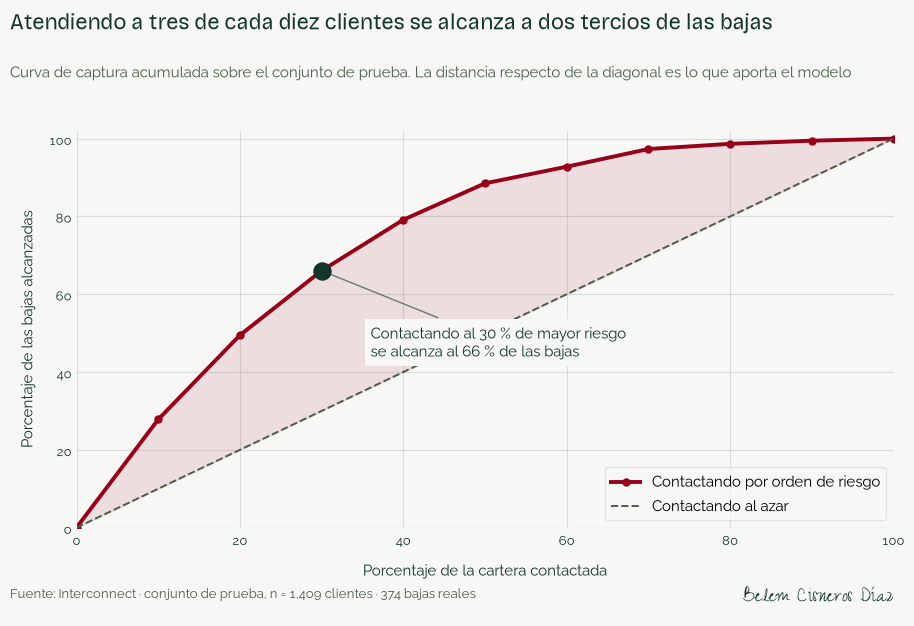

In [31]:
colores = {"fondo": "#F7F7F5", "modelo": "#960018", "azar": "#4A5E48", "acento": "#8A6A72", "texto": "#14352A", "claro": "#E8EBE0"}
fuente_titulo = "Bricolage Grotesque"
fuente_cuerpo = "Raleway"
fuente_firma = "Zeyada"

cartera = np.concatenate([[0], deciles["% de la cartera contactada"].to_numpy()])
capturadas = np.concatenate([[0], deciles["% de las bajas capturadas"].to_numpy()])

fig, ax = plt.subplots(figsize=(9.5, 6.4))
fig.patch.set_facecolor(colores["fondo"])
ax.set_facecolor(colores["fondo"])
fig.subplots_adjust(top=0.76, bottom=0.14, left=0.10, right=0.96)

ax.fill_between(cartera, capturadas, cartera, color=colores["modelo"], alpha=0.10)
ax.plot(cartera, capturadas, color=colores["modelo"], linewidth=2.8, marker="o", markersize=5, label="Contactando por orden de riesgo")
ax.plot([0, 100], [0, 100], color=colores["azar"], linestyle="--", linewidth=1.4, label="Contactando al azar")

destacado = int(deciles.loc[3, "% de las bajas capturadas"])
ax.scatter([30], [deciles.loc[3, "% de las bajas capturadas"]], s=150, color=colores["texto"], zorder=5)
ax.annotate(
    f"Contactando al 30 % de mayor riesgo\nse alcanza al {destacado} % de las bajas",
    xy=(30, deciles.loc[3, "% de las bajas capturadas"]), xytext=(36, 44),
    fontsize=11, fontfamily=fuente_cuerpo, color=colores["texto"],
    arrowprops={"arrowstyle": "-", "color": colores["texto"], "alpha": 0.6},
    bbox={"facecolor": colores["fondo"], "edgecolor": "none", "pad": 4},
)

ax.set_xlabel("Porcentaje de la cartera contactada", fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"], labelpad=10)
ax.set_ylabel("Porcentaje de las bajas alcanzadas", fontsize=10.5, fontfamily=fuente_cuerpo, color=colores["texto"], labelpad=10)
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.tick_params(labelsize=9.5, colors=colores["texto"], length=0)
for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
    etiqueta.set_fontfamily(fuente_cuerpo)
ax.grid(color=colores["texto"], alpha=0.12, linewidth=0.8)
for lado in ax.spines.values():
    lado.set_visible(False)

leyenda = ax.legend(loc="lower right", frameon=True, fontsize=10.5)
leyenda.get_frame().set_facecolor(colores["fondo"])
leyenda.get_frame().set_edgecolor("#E0DDD5")
for texto in leyenda.get_texts():
    texto.set_fontfamily(fuente_cuerpo)

fig.text(0.03, 0.95, "Atendiendo a tres de cada diez clientes se alcanza a dos tercios de las bajas",
         fontsize=15.5, fontfamily=fuente_titulo, color=colores["texto"], ha="left", va="top")
fig.text(0.03, 0.865,
         "Curva de captura acumulada sobre el conjunto de prueba. La distancia respecto de la diagonal es lo que aporta el modelo",
         fontsize=10.5, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left", va="top")
fig.text(0.03, 0.03, f"Fuente: Interconnect · conjunto de prueba, n = {len(y_prueba):,} clientes · {int(y_prueba.sum())} bajas reales",
         fontsize=9, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left")
fig.text(0.96, 0.025, "Belem Cisneros Díaz", fontsize=16, fontfamily=fuente_firma, color=colores["texto"], ha="right")

fig.savefig(RUTA_FIGURAS / "negocio_captura_por_deciles.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

#### 5.4 Qué umbral conviene usar

En la sección 4.1 llegué a que tratar el desbalance es, en el fondo, decidir dónde cortar la lista de riesgo. Quiero resolver esa decisión con dinero y no por costumbre, y es lo que hago aquí.

Llamo **umbral** a la probabilidad a partir de la cual decido contactar a un cliente. Si lo bajo contacto a más gente: alcanzo más bajas y también gasto más promociones en quien no pensaba irse. Si lo subo ocurre lo contrario. No encontré un valor correcto en abstracto, porque depende de cuánto cuesta una promoción y de cuántos clientes la aceptan.

**Dónde elijo el umbral, y por qué ahí.** Hago este cálculo sobre el conjunto de **validación**, no sobre el de prueba. Podría hacerlo en prueba y las cifras se verían algo mejor, pero elegir un umbral es tomar una decisión, y las decisiones de este proyecto se toman en validación: usar la prueba para decidir sería abrirla por segunda vez después de haber prometido abrirla una sola. Una vez elegido el umbral en validación, lo aplico al conjunto de prueba para ver qué habría ocurrido con clientes que el modelo nunca vio. Esa cifra sí es una estimación honesta.

Exploro umbrales entre 0.05 y 0.95 en pasos de 0.01.

**Mis supuestos, declarados como tales.** Interconnect no proporciona estos tres valores, así que no puedo calcularlos: los declaro y los muevo en escenarios.

| Supuesto | Valores que exploro | Por qué elegí estos |
|---|---|---|
| Tasa de aceptación de la oferta | 10 %, 20 %, 30 % | Rango habitual en campañas de retención dirigidas |
| Costo de la promoción | 0.5, 1 y 2 veces el cargo mensual promedio | Equivale a regalar medio mes, un mes o dos meses de servicio |
| Meses adicionales de permanencia de quien acepta | 12 | Horizonte de un año, conservador frente a la antigüedad mediana de 38 meses de los clientes activos |

**La fórmula que uso.** Para cada umbral posible dentro del rango explorado:

```
clientes retenidos = verdaderos positivos × tasa de aceptación
ingreso            = retenidos × cargo mensual promedio de esos clientes × 12 meses
costo              = (verdaderos positivos + falsos positivos) × costo de la promoción
valor neto         = ingreso − costo
```

Comparo el mejor umbral de cada escenario contra las dos alternativas que no requieren modelo: **ofrecer la promoción a todos** y **no ofrecerla a nadie**, cuyo valor neto es cero por definición. Me parece que esa comparación es la que justifica o no la inversión en este proyecto.

In [32]:
ACEPTACION = [0.10, 0.20, 0.30]
FACTORES_DE_COSTO = [0.5, 1.0, 2.0]
MESES_ADICIONALES = 12

validacion_con_riesgo = X_validacion.copy()
validacion_con_riesgo["se_dio_de_baja"] = y_validacion
validacion_con_riesgo["probabilidad_de_baja"] = logistica_final.predict_proba(X_validacion)[:, 1]

cargo_promedio_bajas = float(
    validacion_con_riesgo.loc[validacion_con_riesgo["se_dio_de_baja"] == 1, "MonthlyCharges"].mean()
)
UMBRAL_MINIMO, UMBRAL_MAXIMO = 0.05, 0.95
umbrales = np.round(np.arange(UMBRAL_MINIMO, UMBRAL_MAXIMO + 0.01, 0.01), 2)


def valor_neto(tabla, umbral, tasa_aceptacion, costo_promocion):
    seleccionados = tabla["probabilidad_de_baja"] >= umbral
    acertados = seleccionados & (tabla["se_dio_de_baja"] == 1)
    verdaderos = int(acertados.sum())
    falsos = int((seleccionados & (tabla["se_dio_de_baja"] == 0)).sum())
    if verdaderos + falsos == 0:
        return 0.0, 0, 0
    cargo = float(tabla.loc[acertados, "MonthlyCharges"].mean()) if verdaderos else 0.0
    ingreso = verdaderos * tasa_aceptacion * cargo * MESES_ADICIONALES
    costo = (verdaderos + falsos) * costo_promocion
    return ingreso - costo, verdaderos, falsos


escenarios = []
curvas_de_valor = {}

for tasa_aceptacion in ACEPTACION:
    for factor in FACTORES_DE_COSTO:
        costo_promocion = cargo_promedio_bajas * factor
        valores = [valor_neto(validacion_con_riesgo, u, tasa_aceptacion, costo_promocion)[0] for u in umbrales]
        curvas_de_valor[(tasa_aceptacion, factor)] = valores
        mejor = int(np.argmax(valores))
        valor_mejor, verdaderos, falsos = valor_neto(
            validacion_con_riesgo, umbrales[mejor], tasa_aceptacion, costo_promocion
        )
        valor_a_todos = valor_neto(validacion_con_riesgo, 0.0, tasa_aceptacion, costo_promocion)[0]
        escenarios.append(
            {
                "aceptación": f"{tasa_aceptacion:.0%}",
                "costo de la promoción": f"{factor:g} mes" if factor == 1 else f"{factor:g} meses",
                "umbral óptimo": umbrales[mejor],
                "clientes contactados": verdaderos + falsos,
                "valor neto con el modelo": max(valor_mejor, 0.0),
                "valor neto ofreciendo a todos": valor_a_todos,
                "decisión": "No lanzar la campaña" if valor_mejor <= 0 else f"Contactar desde {umbrales[mejor]:.2f}",
            }
        )

escenarios = pd.DataFrame(escenarios)

ESCENARIOS_EN_PERDIDA = int((escenarios["valor neto ofreciendo a todos"] < 0).sum())
ESCENARIOS_SIN_CAMPANA = int((escenarios["decisión"] == "No lanzar la campaña").sum())
UMBRAL_RECOMENDADO = float(
    escenarios.loc[
        (escenarios["aceptación"] == "20%") & (escenarios["costo de la promoción"] == "1 mes"),
        "umbral óptimo",
    ].iloc[0]
)

metricas["negocio"]["supuestos"] = {
    "tasas_de_aceptacion": ACEPTACION,
    "costo_promocion_en_meses_de_cargo": FACTORES_DE_COSTO,
    "meses_adicionales_de_permanencia": MESES_ADICIONALES,
    "cargo_mensual_promedio_de_las_bajas_en_validacion": round(cargo_promedio_bajas, 2),
    "rango_de_umbrales_explorado": [UMBRAL_MINIMO, UMBRAL_MAXIMO],
    "conjunto_usado_para_elegir_el_umbral": "validación",
}
metricas["negocio"]["escenarios_umbral"] = escenarios.to_dict("records")
metricas["negocio"]["escenarios_en_perdida_si_se_ofrece_a_todos"] = ESCENARIOS_EN_PERDIDA
metricas["negocio"]["umbral_recomendado"] = UMBRAL_RECOMENDADO

print(f"Ofrecer la promoción a toda la cartera produce pérdida en {ESCENARIOS_EN_PERDIDA} de los {len(escenarios)} escenarios.")
print(f"En {ESCENARIOS_SIN_CAMPANA} escenario ningún umbral produce valor positivo: ahí la recomendación es no lanzar la campaña.")
print(f"Umbral recomendado, del escenario intermedio: {UMBRAL_RECOMENDADO:.2f}")

formatear(
    escenarios,
    formatos={
        "umbral óptimo": "{:.2f}",
        "valor neto con el modelo": "{:,.0f}",
        "valor neto ofreciendo a todos": "{:,.0f}",
    },
    indice="aceptación",
)

Ofrecer la promoción a toda la cartera produce pérdida en 7 de los 9 escenarios.
En 1 escenario ningún umbral produce valor positivo: ahí la recomendación es no lanzar la campaña.
Umbral recomendado, del escenario intermedio: 0.73


,costo de la promoción,umbral óptimo,clientes contactados,valor neto con el modelo,valor neto ofreciendo a todos,decisión
aceptación,,,,,,
10%,0.5 meses,0.73,344,"8,724","-19,118",Contactar desde 0.73
10%,1 mes,0.87,101,"1,152","-71,791",Contactar desde 0.87
10%,2 meses,0.95,0,0,"-177,136",No lanzar la campaña
20%,0.5 meses,0.47,651,"33,610","14,437",Contactar desde 0.47
20%,1 mes,0.73,344,"17,448","-38,235",Contactar desde 0.73
20%,2 meses,0.87,101,"2,304","-143,581",Contactar desde 0.87
30%,0.5 meses,0.39,759,"63,215","47,992",Contactar desde 0.39
30%,1 mes,0.56,537,"40,042","-4,680",Contactar desde 0.56
30%,2 meses,0.80,243,"14,647","-110,026",Contactar desde 0.80


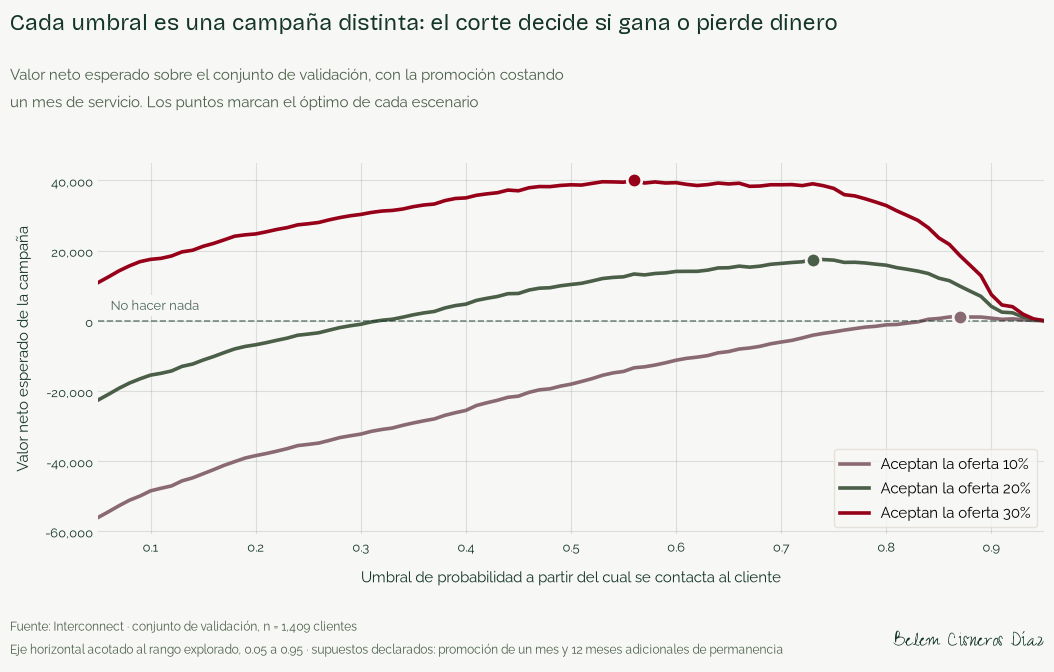

In [33]:
colores = {"fondo": "#F7F7F5", "diez": "#8A6A72", "veinte": "#4A5E48", "treinta": "#960018",
           "texto": "#14352A", "cero": "#14352A"}
fuente_titulo = "Bricolage Grotesque"
fuente_cuerpo = "Raleway"
fuente_firma = "Zeyada"

fig, ax = plt.subplots(figsize=(11, 7))
fig.patch.set_facecolor(colores["fondo"])
ax.set_facecolor(colores["fondo"])
fig.subplots_adjust(top=0.74, bottom=0.21, left=0.11, right=0.97)

for tasa, color in zip(ACEPTACION, [colores["diez"], colores["veinte"], colores["treinta"]]):
    valores = curvas_de_valor[(tasa, 1.0)]
    ax.plot(umbrales, valores, color=color, linewidth=2.6, label=f"Aceptan la oferta {tasa:.0%}")
    mejor = int(np.argmax(valores))
    ax.scatter([umbrales[mejor]], [valores[mejor]], s=110, color=color, zorder=5,
               edgecolor=colores["fondo"], linewidth=2)

ax.axhline(0, color=colores["cero"], linestyle="--", linewidth=1.2, alpha=0.55)
ax.text(0.062, 2200, "No hacer nada", fontsize=9.5, fontfamily=fuente_cuerpo,
        color=colores["texto"], ha="left", va="bottom", alpha=0.75,
        bbox={"facecolor": colores["fondo"], "edgecolor": "none", "pad": 2})

ax.set_xlabel("Umbral de probabilidad a partir del cual se contacta al cliente", fontsize=10.5,
              fontfamily=fuente_cuerpo, color=colores["texto"], labelpad=10)
ax.set_ylabel("Valor neto esperado de la campaña", fontsize=10.5,
              fontfamily=fuente_cuerpo, color=colores["texto"], labelpad=10)
ax.set_xlim(UMBRAL_MINIMO, UMBRAL_MAXIMO)
ax.tick_params(labelsize=9.5, colors=colores["texto"], length=0)
for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
    etiqueta.set_fontfamily(fuente_cuerpo)
ax.yaxis.set_major_formatter(lambda valor, posicion: f"{valor:,.0f}")
ax.grid(color=colores["texto"], alpha=0.12, linewidth=0.8)
for lado in ax.spines.values():
    lado.set_visible(False)

leyenda = ax.legend(loc="lower right", frameon=True, fontsize=10.5)
leyenda.get_frame().set_facecolor(colores["fondo"])
leyenda.get_frame().set_edgecolor("#E0DDD5")
for texto in leyenda.get_texts():
    texto.set_fontfamily(fuente_cuerpo)

fig.text(0.03, 0.96, "Cada umbral es una campaña distinta: el corte decide si gana o pierde dinero",
         fontsize=16, fontfamily=fuente_titulo, color=colores["texto"], ha="left", va="top")
fig.text(0.03, 0.885,
         "Valor neto esperado sobre el conjunto de validación, con la promoción costando\nun mes de servicio. Los puntos marcan el óptimo de cada escenario",
         fontsize=10.5, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left", va="top", linespacing=1.6)
fig.text(0.03, 0.095,
         f"Fuente: Interconnect · conjunto de validación, n = {len(y_validacion):,} clientes\n"
         f"Eje horizontal acotado al rango explorado, {UMBRAL_MINIMO:.2f} a {UMBRAL_MAXIMO:.2f} · supuestos declarados: promoción de un mes y 12 meses adicionales de permanencia",
         fontsize=8.5, fontfamily=fuente_cuerpo, color="#4A5E48", ha="left", va="top", linespacing=1.7)
fig.text(0.97, 0.03, "Belem Cisneros Díaz", fontsize=16, fontfamily=fuente_firma, color=colores["texto"], ha="right", va="bottom")

fig.savefig(RUTA_FIGURAS / "negocio_umbral_valor_esperado.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

In [34]:
costo_promocion_prueba = float(
    prueba_con_riesgo.loc[prueba_con_riesgo["se_dio_de_baja"] == 1, "MonthlyCharges"].mean()
)
predicciones_umbral = (prueba_con_riesgo["probabilidad_de_baja"] >= UMBRAL_RECOMENDADO).astype("int8")

valor_con_umbral, detectados, contactados_de_mas = valor_neto(
    prueba_con_riesgo, UMBRAL_RECOMENDADO, 0.20, costo_promocion_prueba
)
valor_a_todos_prueba = valor_neto(prueba_con_riesgo, 0.0, 0.20, costo_promocion_prueba)[0]

recall_con_umbral = recall_score(y_prueba, predicciones_umbral)
precision_con_umbral = precision_score(y_prueba, predicciones_umbral)

metricas["negocio"]["prueba"]["con_umbral_recomendado"] = {
    "umbral": UMBRAL_RECOMENDADO,
    "clientes_contactados": int(detectados + contactados_de_mas),
    "bajas_detectadas": int(detectados),
    "contactados_que_no_se_iban": int(contactados_de_mas),
    "recall": round(float(recall_con_umbral), 4),
    "precision": round(float(precision_con_umbral), 4),
    "valor_neto": round(float(valor_con_umbral), 2),
    "valor_neto_ofreciendo_a_todos": round(float(valor_a_todos_prueba), 2),
    "diferencia": round(float(valor_con_umbral - valor_a_todos_prueba), 2),
}

metricas["negocio"]["supuestos"]["cargo_mensual_promedio_de_las_bajas_en_prueba"] = round(costo_promocion_prueba, 2)

print(f"UMBRAL {UMBRAL_RECOMENDADO:.2f} APLICADO AL CONJUNTO DE PRUEBA")
print(f"  Cargo mensual promedio de las bajas: {costo_promocion_prueba:.2f} en prueba · {cargo_promedio_bajas:.2f} en validación")
print(f"  Se contactaría a {detectados + contactados_de_mas} de los {len(prueba_con_riesgo):,} clientes")
print(f"  Bajas detectadas: {detectados} de {int(y_prueba.sum())}  ·  Recall {recall_con_umbral:.4f}")
print(f"  Contactados que no se iban: {contactados_de_mas}  ·  Precisión {precision_con_umbral:.4f}")
print(f"  Valor neto: {valor_con_umbral:,.0f}  ·  ofreciendo a todos: {valor_a_todos_prueba:,.0f}")
print(f"  Diferencia a favor de decidir con el modelo: {valor_con_umbral - valor_a_todos_prueba:,.0f}")
print()
print(f"Para comparar, con el umbral predeterminado de 0.50: Recall {resultado_prueba['Recall']:.4f} · Precisión {resultado_prueba['Precisión']:.4f}")

UMBRAL 0.73 APLICADO AL CONJUNTO DE PRUEBA
  Cargo mensual promedio de las bajas: 73.75 en prueba · 74.77 en validación
  Se contactaría a 310 de los 1,409 clientes
  Bajas detectadas: 202 de 374  ·  Recall 0.5401
  Contactados que no se iban: 108  ·  Precisión 0.6516
  Valor neto: 15,216  ·  ofreciendo a todos: -37,717
  Diferencia a favor de decidir con el modelo: 52,932

Para comparar, con el umbral predeterminado de 0.50: Recall 0.7968 · Precisión 0.5256


**Lo que decide esta tabla.** En ocho de los nueve escenarios conviene usar el modelo. En el noveno —aceptación del 10 % con una promoción que cuesta dos meses de servicio— ningún umbral produce valor positivo, y mi recomendación es **no lanzar la campaña**: con esos supuestos, retener sale más caro que perder al cliente.

Lo que me pareció más revelador es otra cosa: en **siete de los nueve escenarios, ofrecer la promoción a toda la cartera produce pérdida**, con cifras que llegan a −177,136. Esa es la situación que Interconnect tiene hoy, cuando no sabe a quién dirigir la oferta. Regalar promociones a todos no solo es peor que usar el modelo: en siete de nueve casos es peor que no hacer nada.

Tomo como recomendación el escenario intermedio, con 20 % de aceptación y una promoción que cuesta un mes de servicio. Su umbral óptimo en validación es **0.73**, y es el que propongo operar.

**Qué ocurre al aplicar ese umbral al conjunto de prueba.** Un apunte sobre el cálculo: al pasar a prueba recalculo el costo de la promoción con el cargo mensual promedio de las bajas de ese conjunto, 73.75, en lugar del de validación, 74.77. Son conjuntos distintos y cada uno debe costearse con sus propios clientes; la diferencia de un peso no mueve ninguna decisión. Con ese cálculo se contactaría a 310 de los 1,409 clientes. De las 374 bajas reales se detectan 202, es decir un Recall de 0.5401, y 65 de cada 100 contactos corresponden a clientes que efectivamente se iban. El valor neto esperado es 15,216 frente a −37,717 si se ofreciera a todos: **52,932 de diferencia entre decidir con el modelo y decidir sin él**.

**Por qué recomiendo 0.73 y no el 0.50 con el que reporto las métricas.** Son dos puntos de operación distintos y conviene no confundirlos. Con 0.50, que es el valor predeterminado del modelo, alcanza un Recall de 0.7968: detecta a 80 de cada 100 clientes que se van, pero solo 53 de cada 100 contactos son acertados. Con 0.73 detecta menos —54 de cada 100— y a cambio acierta en 65 de cada 100. Como cada promoción entregada a quien no pensaba irse cuesta dinero real, el valor neto es mayor con el umbral más exigente. El Recall de 0.7968 describe la capacidad del modelo; el 0.5401 describe la campaña que recomiendo. Ambos son ciertos y responden a preguntas distintas.

Quiero señalar también que el umbral óptimo se mueve entre 0.39 y 0.95 según los supuestos. Por eso no entrego un número único: entrego la regla para calcularlo. Cuando el piloto de la sección 5.6 mida la tasa de aceptación real y el costo real de la promoción, el umbral podrá fijarse con datos en lugar de con supuestos.

#### 5.5 Dónde está el riesgo y qué hacer con cada grupo

El modelo entrega una probabilidad por cliente, pero marketing no diseña una campaña por persona: diseña ofertas por segmento. Por eso crucé, para cada grupo, la tasa de baja realmente observada con la probabilidad promedio que le asigna el modelo. Esta tabla la calculo sobre el conjunto de prueba y la presento como **descripción** de lo que el modelo hace con clientes nuevos, no como insumo de ninguna decisión: las acciones que propongo más abajo se apoyan en las tasas observadas del análisis exploratorio, que se calcularon sobre el registro completo.

**Cómo deben leerse estas dos columnas.** La probabilidad del modelo resulta sistemáticamente más alta que la tasa observada: 68.6 % contra 58.6 % en los clientes de menos de tres meses, 61.9 % contra 42.7 % en el contrato mes a mes. No es un defecto ni un error de cálculo, es la consecuencia directa del ajuste de pesos que apliqué en la sección 4.1: al hacer que los errores sobre la clase minoritaria pesen más, el modelo desplaza todas sus probabilidades hacia arriba. En términos técnicos, mi modelo no está **calibrado**, es decir que sus probabilidades no deben leerse como "este cliente tiene 68 % de probabilidad de irse".

Lo que sí conserva, y es lo que este proyecto necesita, es el **orden**: los segmentos se ordenan igual por una columna que por la otra. El modelo responde correctamente a "¿quién está en mayor riesgo?", que es la pregunta con la que se arma una lista de contacto, y no a "¿cuál es la probabilidad exacta de que este cliente se vaya?". El nivel absoluto lo resuelvo eligiendo el umbral por valor esperado, que es donde esa magnitud se vuelve una decisión. Si en el futuro Interconnect necesitara probabilidades interpretables en términos absolutos, el paso siguiente sería calibrarlas y no cambiar de modelo.

In [35]:
ETIQUETAS_SEGMENTO = {
    "Month-to-month": "Mes a mes", "One year": "Un año", "Two year": "Dos años",
    "Electronic check": "Cheque electrónico", "Mailed check": "Cheque por correo",
    "Bank transfer (automatic)": "Transferencia automática", "Credit card (automatic)": "Tarjeta automática",
    "Fiber optic": "Fibra óptica",
}

segmentacion = prueba_con_riesgo.copy()
segmentacion["Tipo de contrato"] = segmentacion["Type"].replace(ETIQUETAS_SEGMENTO)
segmentacion["Método de pago"] = segmentacion["PaymentMethod"].replace(ETIQUETAS_SEGMENTO)
segmentacion["Servicio de internet"] = segmentacion["InternetService"].replace(ETIQUETAS_SEGMENTO)
segmentacion["Servicios contratados"] = segmentacion["combinacion_servicios"]
segmentacion["Antigüedad"] = pd.cut(
    segmentacion["antiguedad_meses"], [-1, 2, 5, 11, 23, 47, 1000],
    labels=["Menos de 3 meses", "3 a 5 meses", "6 a 11 meses", "12 a 23 meses", "24 a 47 meses", "48 meses o más"],
)

perfiles = []
for dimension in ["Tipo de contrato", "Antigüedad", "Método de pago", "Servicio de internet", "Servicios contratados"]:
    agrupado = segmentacion.groupby(dimension, observed=True).agg(
        clientes=("se_dio_de_baja", "size"),
        tasa_observada=("se_dio_de_baja", "mean"),
        probabilidad_media=("probabilidad_de_baja", "mean"),
        ingreso_mensual=("MonthlyCharges", "sum"),
    )
    for categoria, fila in agrupado.iterrows():
        perfiles.append({
            "dimensión": dimension,
            "segmento": str(categoria),
            "clientes": int(fila["clientes"]),
            "tasa de baja observada": fila["tasa_observada"],
            "probabilidad media del modelo": fila["probabilidad_media"],
            "ingreso mensual": fila["ingreso_mensual"],
        })

perfiles = pd.DataFrame(perfiles).sort_values(
    ["dimensión", "tasa de baja observada"], ascending=[True, False]
).reset_index(drop=True)

metricas["negocio"]["perfiles_por_segmento"] = perfiles.assign(
    **{
        "tasa de baja observada": perfiles["tasa de baja observada"].round(4),
        "probabilidad media del modelo": perfiles["probabilidad media del modelo"].round(4),
        "ingreso mensual": perfiles["ingreso mensual"].round(2),
    }
).to_dict("records")

formatear(
    perfiles,
    formatos={
        "tasa de baja observada": "{:.1%}",
        "probabilidad media del modelo": "{:.1%}",
        "ingreso mensual": "{:,.2f}",
    },
    indice="dimensión",
)

,segmento,clientes,tasa de baja observada,probabilidad media del modelo,ingreso mensual
dimensión,,,,,
Antigüedad,Menos de 3 meses,174,58.6%,68.6%,"9,228.25"
Antigüedad,3 a 5 meses,85,50.6%,68.5%,"4,839.25"
Antigüedad,12 a 23 meses,213,30.5%,51.8%,"12,376.45"
Antigüedad,6 a 11 meses,168,30.4%,58.2%,"9,666.45"
Antigüedad,24 a 47 meses,326,19.6%,36.6%,"21,221.40"
Antigüedad,48 meses o más,443,11.1%,16.9%,"31,516.65"
Método de pago,Cheque electrónico,461,44.7%,64.2%,"34,591.80"
Método de pago,Cheque por correo,316,19.3%,31.8%,"13,041.80"
Método de pago,Tarjeta automática,306,18.6%,27.4%,"19,963.40"


**Las acciones que propongo.** Cada segmento de alto riesgo admite una oferta distinta, y ahí veo la diferencia entre una campaña genérica y una campaña que funciona. Las figuras de la sección 1.5 y la tabla anterior sostienen cada una de estas recomendaciones:

| Segmento | Evidencia | Acción que propongo |
|---|---|---|
| Contrato mes a mes | 42.7 % de baja frente a 2.8 % del contrato a dos años; concentra el 88.6 % de todas las bajas | Incentivo explícito de migración: meses bonificados o descuento permanente por firmar a un año. Me parece la palanca más rentable que tiene Interconnect |
| Clientes con menos de tres meses | 58.4 % de baja, la tasa más alta del registro | Programa de bienvenida con contacto en el primer y el segundo mes de servicio. El riesgo se decide al inicio, no cuando el cliente avisa |
| Pago con cheque electrónico | 45.3 % de baja frente a 15.2 % de quienes pagan con tarjeta automática | Migración a domiciliación bancaria con un beneficio asociado. El pago automático reduce la fricción mensual que precede a la cancelación |
| Fibra óptica | 41.9 % de baja frente a 19.0 % de DSL, con un cargo mensual más alto | Revisión de la relación precio-valor: empaquetar soporte técnico o antivirus sin costo antes de considerar un descuento directo |
| Solo internet, sin línea telefónica | 24.9 % de baja, frente a 7.4 % de quienes solo tienen teléfono | Venta cruzada de línea telefónica con tarifa preferente. Más servicios contratados equivalen a más razones para quedarse |

Hago una advertencia necesaria para interpretar esta tabla: mi modelo identifica **riesgo**, no causa. Que la fibra óptica aparezca asociada a más bajas no significa que la fibra provoque la fuga; significa que es el servicio más caro y que quienes lo contratan son más sensibles al precio. Confundir correlación con causa llevaría a cancelar la fibra en lugar de ajustar su propuesta de valor.

#### 5.6 Cómo llevarlo a producción

| Decisión | Lo que propongo |
|---|---|
| **Frecuencia de cálculo** | Mensual, con el cierre de facturación. La antigüedad y los cargos cambian mes a mes, y el riesgo con ellos |
| **Umbral inicial** | 0.73, el óptimo del escenario intermedio sobre validación. Se recalibra en cuanto el piloto entregue la tasa de aceptación real |
| **Piloto con grupo de control** | Dividir la lista de riesgo en dos mitades al azar: una recibe la oferta y la otra no. La diferencia de permanencia entre ambas es el efecto real de la promoción, no el que se le atribuye |
| **Métricas de seguimiento** | Tasa de baja de cada grupo, tasa de aceptación de la oferta, costo por cliente retenido y valor neto efectivo contra el esperado |
| **Reentrenamiento** | Cuando el AUC-ROC sobre datos nuevos caiga por debajo de 0.80, o cada seis meses, lo que ocurra primero |
| **Limitación declarada** | El modelo dice quién está en riesgo. No dice si la promoción funcionará: eso solo lo puede responder el piloto con grupo de control |

Insisto en el grupo de control porque no lo considero un detalle metodológico: es lo que separa "retuvimos al 70 % de los contactados" de "retuvimos al 70 %, pero el 65 % se habría quedado de todos modos". Sin él, cualquier cifra de éxito que se reporte sería inverificable.

## Etapa 3 · Informe de solución

*Dirigido al equipo de marketing de Interconnect.*

### El modelo que elegí y por qué

Probé cuatro modelos y me quedé con el más sencillo de los que funcionan: una **regresión logística**. Los dos modelos basados en árboles de decisión quedaron por delante en la métrica principal por un margen de entre 0.001 y 0.002, ocho veces menor que la variación que produce la propia forma de medir. En otras palabras, no hay evidencia de que sean mejores.

Ante ese empate pesaron tres razones prácticas. Detecta más clientes en riesgo que cualquiera de los otros. Se puede explicar: ante cualquier cliente señalado es posible decir qué pesó para que apareciera en la lista, algo que un conjunto de 637 árboles no permite. Y es barato de mantener, porque entrena en segundos y no exige infraestructura especial.

### Lo que el modelo hace, medido

Reservé desde el principio un grupo de 1,409 clientes que el modelo nunca vio y lo abrí una sola vez, al final. Por eso estas cifras son las que cabe esperar con clientes nuevos y no un reflejo de los datos con los que aprendió.

| Métrica | Resultado | Qué significa para la operación |
|---|---|---|
| AUC-ROC | **0.8421** | Tomando al azar un cliente que se fue y uno que se quedó, el modelo le asigna más riesgo al que se fue en 84 de cada 100 casos. Es la medida de qué tan bien ordena la cartera por riesgo |
| Recall | **0.7968** | De cada 100 clientes que cancelan, el modelo identifica 80 a tiempo |
| Precisión | **0.5256** | De cada 100 clientes señalados, 53 se iban de verdad |

Estas tres cifras corresponden al corte predeterminado del modelo, 0.50. Para operar la campaña recomiendo un corte más exigente, **0.73**, elegido maximizando el valor neto esperado. Con ese corte, sobre el mismo grupo de 1,409 clientes, el modelo detecta 202 de las 374 cancelaciones y acierta en 65 de cada 100 contactos: detecta menos y se equivoca mucho menos. Más abajo está la razón económica de preferirlo.

### Qué significa el Recall en su operación

Un Recall de 0.7968 quiere decir que, de las 374 cancelaciones del periodo medido, el modelo habría anticipado 298 y se le habrían escapado 76.

Esas 76 son el costo real del error: clientes que se fueron sin que nadie les ofreciera nada. Conviene mirar también su peso económico y no solo su número. Las cancelaciones que el modelo no detecta facturaban en promedio 66.91 mensuales, frente a 75.50 de las que sí detecta. Por eso el modelo alcanza el **81.6 % del ingreso mensual en fuga**, por encima del 79.7 % de los clientes: se le escapan los de menor valor.

Con el corte de operación que recomiendo, 0.73, la lista baja a 310 clientes y se detectan 202 de las 374. Se renuncia a alcanzar a 96 clientes a cambio de no gastar promociones en 161 que no pensaban irse.

### Qué pasaría si lo usaran hoy

Primero, la dimensión del problema. Los clientes que ya se dieron de baja representaban **139,130.85 de ingreso mensual**, el 30.5 % de los 456,116.60 que suman los cargos mensuales de todo el registro, activos y dados de baja incluidos. La cartera que sigue activa factura 316,985.75 mensuales. Casi un tercio de la facturación registrada correspondía a clientes que terminaron yéndose.

Segundo, el esfuerzo necesario. No hace falta contactar a toda la cartera: **atendiendo al 30 % de clientes con mayor riesgo se alcanza al 66 % de quienes se van.** Contactando a ese mismo 30 % sin criterio solo se encontraría al 30 %.

Tercero, y es lo más importante para decidir un presupuesto: **ofrecer promociones a toda la cartera produce pérdida en siete de los nueve escenarios evaluados**, con cifras que llegan a −177,136. Esa es la situación actual, cuando no se sabe a quién dirigir la oferta. Tomando el escenario intermedio —que una de cada cinco personas acepte la oferta y que la promoción cueste un mes de servicio— el corte que maximiza el valor neto es 0.73: contacta a 310 de los 1,409 clientes y deja un valor neto esperado de 15,216, frente a −37,717 si se ofreciera a todos. **La diferencia entre decidir con el modelo y decidir sin él es de 52,932 en ese escenario.**

Hay un noveno escenario donde la respuesta es no actuar: si solo una de cada diez personas acepta y la promoción cuesta dos meses de servicio, ningún corte produce valor positivo y conviene no lanzar la campaña. Una herramienta que solo supiera decir "contacte a estos" no serviría para decidir un presupuesto; esta también dice cuándo no vale la pena gastar.

### Dónde actuar primero

| Prioridad | Segmento | Acción |
|---|---|---|
| 1 | Contrato mes a mes: 42.7 % de baja y el 88.6 % de todas las cancelaciones | Incentivo de migración a contrato anual con meses bonificados |
| 2 | Clientes con menos de tres meses: 58.4 % de baja | Programa de bienvenida con contacto en el primer y segundo mes |
| 3 | Pago con cheque electrónico: 45.3 % de baja | Migración a domiciliación bancaria con un beneficio asociado |
| 4 | Fibra óptica: 41.9 % de baja | Empaquetar soporte técnico o antivirus antes de ofrecer descuento |

### Limitaciones y siguientes pasos

Hay cuatro cosas que este modelo no resuelve, y conviene tenerlas presentes antes de comprometer presupuesto:

1. **Identifica riesgo, no causa.** Que la fibra óptica concentre cancelaciones no significa que la fibra las provoque: es el servicio más caro y atrae a clientes sensibles al precio. La acción correcta es revisar su propuesta de valor, no retirar el producto.
2. **No garantiza que la promoción funcione.** Predice quién está por irse, no quién se quedará si recibe una oferta. Solo un piloto con grupo de control puede medir eso.
3. **Las cifras de dinero dependen de tres supuestos declarados:** la tasa de aceptación de la oferta, el costo de la promoción y los meses adicionales de permanencia de quien acepta. Ninguno está en los datos, así que los presenté en escenarios en lugar de un número único. En cuanto el piloto entregue los valores reales, el corte se recalcula con ellos.
4. **Los datos llegan hasta el 1 de febrero de 2020 y tienen granularidad mensual.** El modelo debe reentrenarse con información reciente antes de operar, y volver a hacerlo cuando su AUC-ROC sobre datos nuevos caiga por debajo de 0.80.

**El siguiente paso que recomiendo** es un piloto de un trimestre: calcular las probabilidades con el cierre de facturación, dividir al azar la lista de riesgo en dos mitades, ofrecer la promoción solo a una y comparar la permanencia de ambas. Ese experimento convierte los supuestos de este informe en números propios de Interconnect y permite fijar el corte definitivo.

## Anexos del proyecto

### Tabla de recursos

| Recurso | Ubicación | Contenido | ¿Se versiona? |
|---|---|---|---|
| Notebook del análisis | `notebooks/interconnect_fuga_clientes.ipynb` | Este documento completo: plan, código, informe y capa de negocio | Sí |
| Figuras | `figures/` | Las nueve figuras del notebook en PNG a 150 ppp (puntos por pulgada, la densidad de impresión), exportadas por el propio notebook al ejecutarse | Sí |
| Métricas | `resultados/metricas.json` | Fuente única de todos los números del proyecto: EDA, particiones, baseline, modelos optimizados, resultado final, importancia de variables y cifras de negocio | Sí |
| Tipografías | `assets/fuentes/` | Bricolage Grotesque, Raleway y Zeyada en formato `.ttf`, registradas en matplotlib sin instalarse en el sistema | Sí |
| Datos de origen | `data/` | `contract.csv`, `personal.csv`, `internet.csv`, `phone.csv` | **No.** Se descargan del [archivo comprimido original](https://practicum-content.s3.us-west-1.amazonaws.com/new-markets/Spreadsheets_for_DA/datasets/final_provider.zip) y se colocan en `data/` |

### Entorno de ejecución

Desarrollé el notebook en un entorno conda dedicado con Python 3.11. Las versiones exactas de pandas, numpy, scikit-learn, LightGBM, matplotlib y seaborn se imprimen en la sección 1.1 al ejecutarse, de modo que siempre corresponden al entorno real y no a una lista escrita a mano.

Para ejecutarlo en otro entorno el requisito mínimo es **scikit-learn 1.2 o superior**, que impone el parámetro `sparse_output` del codificador One-Hot: en versiones anteriores ese parámetro se llamaba `sparse`. Verifiqué que retirarlo no altera los resultados —el AUC-ROC de prueba se mantiene en 0.8421 y el Recall en 0.7968—, y lo conservo porque hace explícito que la matriz resultante es densa.

La carga de datos admite dos rutas: primero `/datasets/final_provider/` y, si no existe, `../data/` relativa a la carpeta `notebooks/`. El notebook se ejecuta completo, de principio a fin, en cualquiera de las dos.

### Enlaces

| Destino | Enlace |
|---|---|
| Repositorio del proyecto | https://github.com/he1109-ci3l0/interconnect-fuga-clientes |
| Case study | https://he1109-ci3l0.github.io/interconnect-fuga-clientes/ |
| Datos de origen | https://practicum-content.s3.us-west-1.amazonaws.com/new-markets/Spreadsheets_for_DA/datasets/final_provider.zip |

### Registro de las cifras

La última celda guarda `resultados/metricas.json` y enumera las figuras que el notebook acaba de exportar. Dejo este paso al final a propósito: así el archivo recoge todas las cifras del documento, incluidas las de la capa de negocio, en una sola escritura y sin versiones intermedias.

In [36]:
RUTA_RESULTADOS = Path("../resultados")
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

with open(RUTA_RESULTADOS / "metricas.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas, archivo, ensure_ascii=False, indent=2)

print("Registro completo guardado en", (RUTA_RESULTADOS / "metricas.json").resolve())
print("Secciones:", ", ".join(metricas))
print("Figuras exportadas a", RUTA_FIGURAS.resolve())
for figura in sorted(RUTA_FIGURAS.glob("*.png")):
    print("  ", figura.name)

Registro completo guardado en /Users/belem/interconnect-fuga-clientes/resultados/metricas.json
Secciones: fecha_corte, n_clientes, tasa_baja, eda, particiones, baseline, optimizados, final, importancia_por_permutacion, negocio
Figuras exportadas a /Users/belem/interconnect-fuga-clientes/figures
   baseline_curvas_roc.png
   eda_bajas_por_antiguedad.png
   eda_bajas_por_contrato.png
   eda_bajas_por_pago_e_internet.png
   eda_balance_objetivo.png
   final_importancia_variables.png
   final_matriz_y_roc_prueba.png
   negocio_captura_por_deciles.png
   negocio_umbral_valor_esperado.png
